# Предсказание растворимости органических молекул

Предсказание LogS(mol/L) по структуре молекулы, растворителю и температуре на данных BigSolDB 2.0. Подробности, результаты и выводы — в README репозитория.


# Описание задачи
В этом задании вам предлагается решить одну из классических проблем хемоинформатики - предсказание растворимостей органических молекул. Для задания мы возьмем одну из наиболее современных и верифицированную вручную базу данных растворимостей **BigSolDB2.0**. Вашей задачей будет научиться предсказывать растворимость (**LogS(mol/L)**) по введенным параметрам. 

Чтобы сэкономить время расчётов, мы не будем заниматься кросс-валидацией и тем, что в ML называется *ablation studies* - об успехе учебной задачи будем судить на обычном holdout-тесте, мотивируя выбор архитектуры интуицией/здравым смыслом/поведением модели на holdout-валидации. В остальном этот проект представляет собой наиболее приближенный к практике бейзлайн исследования данных и обучения моделей в современной хемоинформатики.

In [2]:
# Импорты
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Загрузка данных
original_df = pd.read_csv('BigSolDBv2.0.csv')
# Нужные столбцы
original_columns = {'SMILES_Solute', 'SMILES_Solvent', 'Solvent', 'Temperature_K', 'LogS(mol/L)', 'Source'}

In [4]:
original_df.shape

(103944, 12)

In [5]:
original_df.head()

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,FDA_Approved,Source
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.0006,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
1,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,314.65,ethanol,CCO,0.0012,0.020100,-1.696799,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
2,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,319.15,ethanol,CCO,0.0020,0.033356,-1.476824,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
3,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,322.15,ethanol,CCO,0.0050,0.083356,-1.079064,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
4,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,324.15,ethanol,CCO,0.0139,0.233286,-0.632111,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573


То есть у нас в таблице есть 12 столбцов и 103944 строк, в столбцах содержится:
1) SMILES_Solute — SMILES representation of the solute molecule
2) Temperature_K — temperature for the reported solubility value, K
3) Solvent — solvent name
4) SMILES_Solvent — SMILES representation of the solvent molecule
5) Solubility(mole_fraction) — the reported solubility value expressed in mole fraction of solute (то есть по факту это просто доля количесва вещества от общего количества, котрое перешло в раствор)
6) Solubility(mol/L) — the recalculated solubility value expressed in molar concentration of solute (mol/L) (просто концентрация расворенного вещества в растворе)
7) LogS(mol/L) — decimal logarithm of the recalculated solubility value expressed in molar concentration of solute (mol/L)
8) Compound_Name — solute name
9) CAS — solute CAS number
10) PubChem_CID — solute PubChem_CID
11) FDA_Approved — designation if the solute is a FDA approved drug. ‘Yes’ is stated for FDA approved drugs while ‘No’ is stated for others.
12) Source — DOI of a data source for given values.

Эта информация взята из открытого источника: https://zenodo.org/records/15094979.
Нас интересуют предсказания 7 столбца, если я правильно понял

### Задача 1: Предварительное исследование базы данных (3 балла)
Проведите анализ записей в базе данных с позиции целевых значений (то есть занчений седьмого столбца) и представленных структур молекул (SMILES_Solute) и растворителей (SMILES_Solvent). В качестве признаков для молекул вы используйте те дескрипторы/фингерпринты, которые вам нравятся и кажутся подходящими для решения данной задачи. Не забудьте убедиться, что вы **корректно** анализируете структуры - все SMILES должны быть каноничными, не должно быть бесконечных, NaN или стационарных по всей выборке дескрипторов.

Решение и выводы должны отвечать как минимум на следующие вопросы:
 - Сколько уникальных записей БД содержит для наиболее популярных и наименее популярных растворителей? Сколько среди них уникальных молекул?
 - Сколько всего источников приведено в БД? Каково распределение количества известных значений по источникам?
 - Каково распределение температур в данных? Если существуют ли какая-то наиболее частая температура (с учетом погрешности в 1К), корректно ли на их основе решать задачу предсказания растворимости при данной фиксированной температуре?
 - Какие молекулы представлены в базе данных? Каков их элементный состав? Для ответа на этот вопрос самостоятельно выберите интересующие вас статистики дескрипторов.
 - Присутствуют ли явные "выбросы" среди молекул? Если да, что это за молекулы?

In [6]:
#ваш код здесь. Начну с выбора дикрипторов. В задании сказано, 
# что нужно исопльзовать те дискрипторы, котрые не содержат NaN, поэтому смотрим на количество пропусков в каждоом столбце:
original_df.isna().sum()

SMILES_Solute                   0
Temperature_K                   0
Solvent                         0
SMILES_Solvent                  0
Solubility(mole_fraction)       0
Solubility(mol/L)            2961
LogS(mol/L)                  2961
Compound_Name                   0
CAS                          7456
PubChem_CID                  2593
FDA_Approved                    0
Source                          0
dtype: int64

Очев, что Solubility(mol/L) теперь использовать нельзя, так что логичнее всего остановится на Solubility(mole_fraction), но надо проверить еще количество динаковых значений в нем.

In [7]:
original_df['Solubility(mole_fraction)'].var()

0.011348592275835349

Собственно мы получили инфу о том, что у Solubility(mole_fraction) есть какая-то дисперсия, это радует, так как это значит, что зачения дискриптора не постоянное, а значит его можно использовать.

In [8]:
solvents = original_df['Solvent'].value_counts()
the_most_popular_solvent= solvents.idxmax()
the_least_popular_solvent= solvents.idxmin()
print(f'Самый популярный растворитель: {the_most_popular_solvent}')
print(f'Самый не популярный растворитель: {the_least_popular_solvent}')

Самый популярный растворитель: ethanol
Самый не популярный растворитель: cyclopentanol


In [9]:
individual_records_for_the_most_popular_solvent = 0
smiles_for_the_most_popular_solvent = []
for i in range(len(original_df)):
    if original_df['Solvent'][i] == the_most_popular_solvent and original_df['SMILES_Solute'][i] not in smiles_for_the_most_popular_solvent:
        smiles_for_the_most_popular_solvent.append(original_df['SMILES_Solute'][i])
        individual_records_for_the_most_popular_solvent += 1
print(f'Уникальных молекул для самого популярного растворителя: {len(smiles_for_the_most_popular_solvent)}')

Уникальных молекул для самого популярного растворителя: 1016


In [10]:
individual_records_for_the_least_popular_solvent = 0
smiles_for_the_least_popular_solvent = []
for i in range(len(original_df)):
    if original_df['Solvent'][i] == the_least_popular_solvent and original_df['SMILES_Solute'][i] not in smiles_for_the_least_popular_solvent:
        smiles_for_the_least_popular_solvent.append(original_df['SMILES_Solute'][i])
        individual_records_for_the_least_popular_solvent += 1
print(f'Уникальных молекул для самого не популярного растворителя: {len(smiles_for_the_least_popular_solvent)}')

Уникальных молекул для самого не популярного растворителя: 1


Это вполне себе можно проверить:

И такой расворитель правда используется только один раз

In [11]:
print(original_df[original_df['Solvent']==the_least_popular_solvent])

                     SMILES_Solute  Temperature_K        Solvent  \
103936  O=[N+]([O-])c1cccc2ccccc12         298.15  cyclopentanol   

       SMILES_Solvent  Solubility(mole_fraction)  Solubility(mol/L)  \
103936       OC1CCCC1                    0.05988                NaN   

        LogS(mol/L)       Compound_Name      CAS  PubChem_CID FDA_Approved  \
103936          NaN  1-nitronaphthalene  86-57-7       6849.0           No   

                           Source  
103936  10.1007/s10953-005-7691-2  


In [12]:
the_unique_sources = []
for i in range(len(original_df)):
    if original_df['Source'][i] not in the_unique_sources:
        the_unique_sources.append(original_df['Source'][i])
print(f'Уникальных источников: {len(the_unique_sources)}')

Уникальных источников: 1595


In [13]:
source_counts=original_df['Source'].value_counts()
source_counts

Source
10.1021/je100341q                568
10.1016/j.molliq.2018.12.081     392
10.1021/je1009812                340
10.1016/j.jct.2013.12.031        324
10.1016/j.jct.2014.05.009        288
                                ... 
10.1016/j.molliq.2012.12.028       2
10.1016/S0378-3812(97)00039-3      2
10.1021/je030165y                  2
10.1006/jcht.1996.0108             1
10.1021/je000316m                  1
Name: count, Length: 1595, dtype: int64

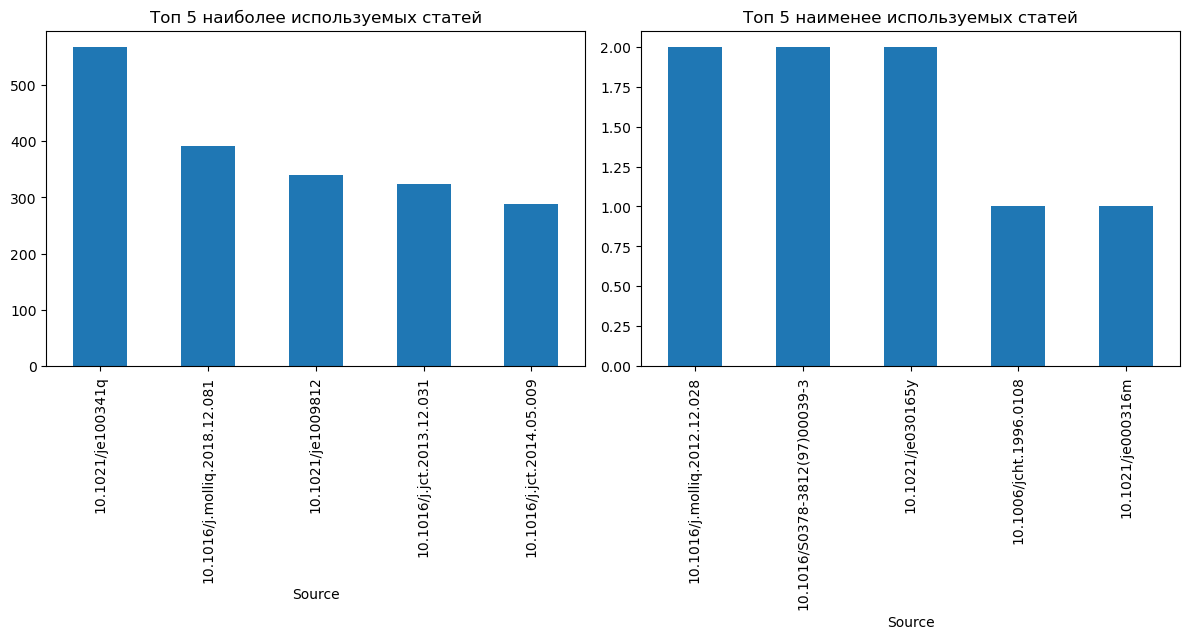

In [14]:
#можно конечно и так:
#source_counts.plot.bar(x='Источники')
#plt.show()
#но график получается вообще не читаемым, поэтому я решил вывести первые 5 и последние 5 источников
plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
plt.title("Топ 5 наиболее используемых статей")
source_counts.head().plot.bar()
plt.subplot(2,2,2)
plt.title("Топ 5 наименее используемых статей")
source_counts.tail().plot.bar()
plt.tight_layout()
plt.show()



Text(0.5, 1.0, 'Исходное распределение\n"Temperature_K"')

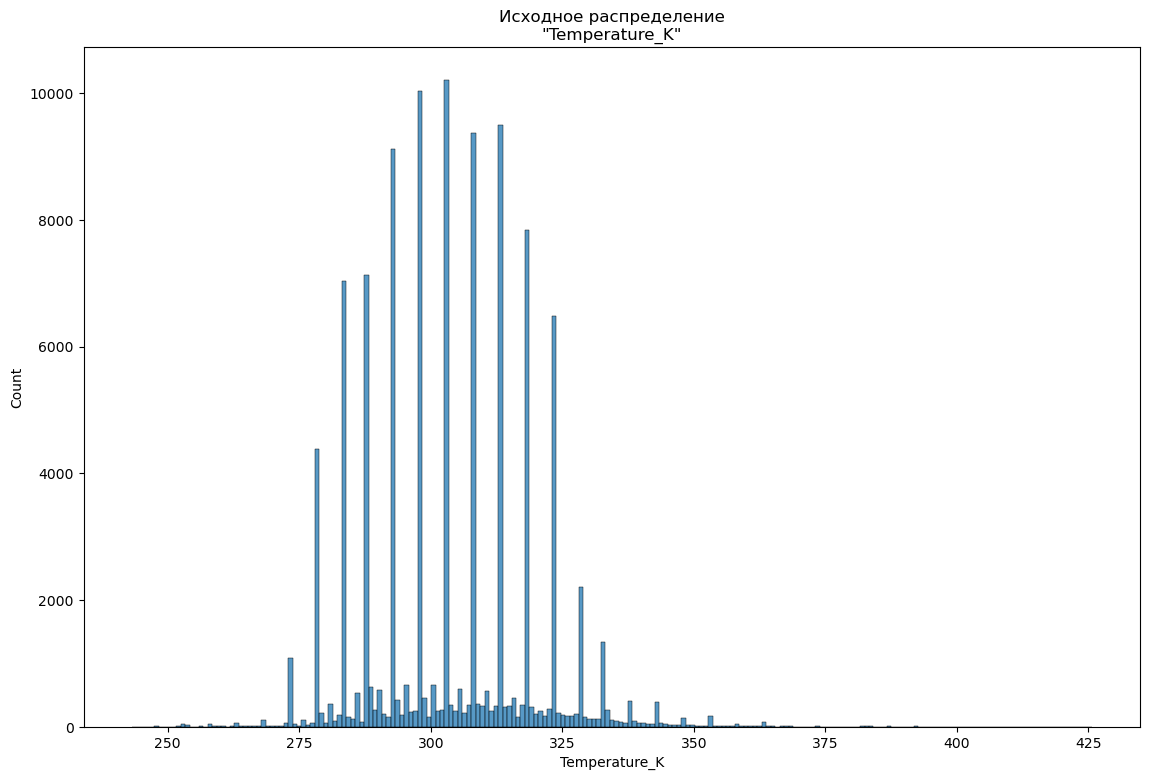

In [15]:
plt.figure(figsize=(30,30))
plt.subplot(3,2,1)
sns.histplot(original_df['Temperature_K'])
plt.title(f'Исходное распределение\n"{'Temperature_K'}"')

In [16]:
original_df.shape[0]

103944

In [17]:
#Нахождение наиболее частой температуры - это по факту нахождение моды с учетом погрешности:
bins = pd.cut(original_df['Temperature_K'], bins=range(0, original_df.shape[0], 1))#собственно разбиваю столбик температуры на бины с начала по самый конец датафрейма с шагом 1 и нахожу наиболее частый
top_temp = bins.mode()
print(top_temp)
#Получаю 303-304 градуса по Кельвину, что согласуется с нашей диаграмкой общего распределения температуры

0    (303, 304]
Name: Temperature_K, dtype: category
Categories (103943, interval[int64, right]): [(0, 1] < (1, 2] < (2, 3] < (3, 4] ... (103939, 103940] < (103940, 103941] < (103941, 103942] < (103942, 103943]]


Корректно ли на их основе решать задачу предсказания растворимости при данной фиксированной температуре?
В результате моих расчетов получилось, что наибольшее количесвто измерений проводилось при 303-304К, однако в моем распределении температур видно, что в датафреме присуствует большое количество других довольно распространенных температур, котрые отличаются от 303-304К. Найдим первые 10 мод:

In [18]:
bins.value_counts().sort_values(ascending=False).head(10)

Temperature_K
(303, 304]    10164
(298, 299]     9939
(313, 314]     9474
(308, 309]     9369
(293, 294]     9323
(318, 319]     7792
(288, 289]     7600
(283, 284]     7087
(323, 324]     6458
(278, 279]     4392
Name: count, dtype: int64

In [19]:
sum(bins.value_counts().sort_values(ascending=False).head(10))

81598

Соответственно, у меня есть 81598 наблюдений в диапазоне 278-309К - это больше погрешнрсти в 1К, а значит предсказывать растворимость тольок основе моды в 303-304К нельзя.

In [20]:
original_df.head(5)

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,FDA_Approved,Source
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.0006,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
1,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,314.65,ethanol,CCO,0.0012,0.020100,-1.696799,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
2,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,319.15,ethanol,CCO,0.0020,0.033356,-1.476824,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
3,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,322.15,ethanol,CCO,0.0050,0.083356,-1.079064,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
4,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,324.15,ethanol,CCO,0.0139,0.233286,-0.632111,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573


In [21]:
#какие молекулы представлены в базе данных? 
# По факту эта задача класстеризации, надо выьрать дискрипторы, которые смогут различать наши молекулы.
# Самое логично в этом пункте - разбить нашу выборку кластеры по растворимости, а для этого лучше всего подойдет столбец Solubility(mole_fraction). 
# Потому что все остальные столбцы, котрые могут быть дискрипторами, содержат пропуски.
median=original_df['Solubility(mole_fraction)'].median()
classes=(original_df['Solubility(mole_fraction)']>median).astype(int)
print(classes.value_counts())
#В результате получаю практически одинаковое распределение по двум классам

Solubility(mole_fraction)
0    51975
1    51969
Name: count, dtype: int64


In [22]:
# С другой стороны это задание можно решить интреснее: можно использовать пакет RDkit, и находить в нашем SMILES коде различные паттерны, это я тоже сделаю, 
# потому что мне кажется6 что это сильно интереснее в сравнении с обычным бинарным >< медианы,
# также пожно считать элементный состав нашего соединения и по массе конретных элементов в ней описывать наш даатфрейм
# Однако также надо учитывать, что наш датафрейм содержит большое количесвто повторяющихся соединений (это связано с тем, что растворимость для 
# них меряли при разных температурах), так что чтобы избежать искуссвенного накручивания соединений в каком-либо 
# классе, я предварительно оставлю тольок уникальные записи соединений в датафрейме (тут мне неважно, 
# какая конкретно температура будет в датафреме для конкретного соединения)
unique_df = original_df.drop_duplicates(subset=['SMILES_Solute'])
unique_df
from rdkit import Chem
from rdkit.Chem import Descriptors
def has_group (smiles):
    patterns = Chem.MolFromSmiles('C=O')
    mol =Chem.MolFromSmiles(smiles)
    if patterns is None:
        return None
    return int(mol.HasSubstructMatch(patterns))
unique_df['Class']=unique_df['SMILES_Solute'].apply(has_group)
print(f'Разделение соединений в датафреме по наличию/отсутствию карбонильной группы (1-карбонильная группа есть, 0-карбонильной группы нет): {unique_df['Class'].value_counts()}')

Разделение соединений в датафреме по наличию/отсутствию карбонильной группы (1-карбонильная группа есть, 0-карбонильной группы нет): Class
1    864
0    584
Name: count, dtype: int64


/var/folders/yr/m_d68fx97qs74rxj0k9qk39h0000gn/T/ipykernel_3389/1402419697.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_df['Class']=unique_df['SMILES_Solute'].apply(has_group)


Соотвественно мы понимаем, что у 864 соединений в нашем датафрейме есть карбонильная группа, у 584 соединений ее нет. Таким образом можно найти любой функциональная фрагмент в соединениях и таким образом разбить датафрейм на классы.
Но тут мы сталкиваемся с другой проблемой: мы не можем нормально оценить выбросы в нашем датафрейме: для этого нужны какие-либо численные значения, для этого я хочу посчитать элементый анализ всех соединений в unique_df.

In [23]:
from rdkit.Chem import rdMolDescriptors
def get_formula(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return rdMolDescriptors.CalcMolFormula(mol)
unique_df['Brutto_Formula']=unique_df['SMILES_Solute'].apply(get_formula)
def get_molarmass(smiles):
    mol=Chem.MolFromSmiles(smiles)
    return Descriptors.MolWt(mol)
unique_df['Mollar_Mass']=unique_df['SMILES_Solute'].apply(get_molarmass)

/var/folders/yr/m_d68fx97qs74rxj0k9qk39h0000gn/T/ipykernel_3389/18677883.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_df['Brutto_Formula']=unique_df['SMILES_Solute'].apply(get_formula)
/var/folders/yr/m_d68fx97qs74rxj0k9qk39h0000gn/T/ipykernel_3389/18677883.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_df['Mollar_Mass']=unique_df['SMILES_Solute'].apply(get_molarmass)


In [24]:
#напишем функции для подсчета процента угелрода в наших соединениях:
# но сначала нам надо написать функцию для того , чтобы распарсить строку Брутто формулы на словарь:
#это удобнее всего делать через регулярные выражения, я с ними раньше не работал, но как я понимаю, я просто задаю общий формат записи, котрый моя функция будет искать в строке
import re
def C_share(Brutto_Fromula, mol_weight):
    pattern=re.findall(r'([A-Z][a-z]?)(\d*)',Brutto_Fromula) #объясняю, почему я так написал: я использую метод findall, он проходит по строке, котруб я ему даю и ищет фрагементы, 
    # подходщие под следующий шаблон: вначале какая-то большшая буква от A до Z, потом 0 или одно вхождение (за это отвечает ?) еще одной буквы уже маленьким регистром. После всего этого идет какое-то число
    # тут также очень важно наличие скобок: благодяря им регулярное выражение возвращает как бы отдельно два значения: сам символ атома и его количесвто в Брутто-формуле 
    C_count=0 #это у нас просто счетчик угелродов в каждой конкретной молекулке
    for elem, count in pattern: #пробеггаюсь по каждой паре элемент/его количество
        count = int(count) if count else 1 #если у нас есть хоть что-то записанной в count, то перевожу это в int,
        # если в count пустая строка, то присваиваю ей значение 1 (ведь строку формата СН4 моя регулярка разобьет на ("C", ""), ("H", "4"), значит у нас 1 углерод)
        if elem == "C":
            C_count = count
    atomic_weight_C = Chem.GetPeriodicTable().GetAtomicWeight("C") #Из RDkit достаю молярку углерода, на самом 
    # деле это можно было бы сделать проще, просто умножая количество атомов на 12, но я решил наптсать здесь функцию в самом общем виде, то есть по факту сейчас я могу размножить эту же функцию на любые элементы, кроме углерода, и мне не придется гуглить их молярную массу
    wC = (C_count * atomic_weight_C / mol_weight) * 100.0
    return wC
unique_df['C_mass_pct'] = unique_df.apply(lambda row: C_share(row['Brutto_Formula'], row['Mollar_Mass']),axis=1)

/var/folders/yr/m_d68fx97qs74rxj0k9qk39h0000gn/T/ipykernel_3389/1346133565.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_df['C_mass_pct'] = unique_df.apply(lambda row: C_share(row['Brutto_Formula'], row['Mollar_Mass']),axis=1)


In [25]:
unique_df

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,FDA_Approved,Source,Class,Brutto_Formula,Mollar_Mass,C_mass_pct
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.000600,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573,1,C22H44O3,356.591,74.102263
5,CCCCCCCCCCCCCCCCCCCCCC(=O)OCCO,296.35,ethanol,CCO,0.000100,0.001708,-2.767540,Ethylene glycol monobehenate,109376-47-8,18769590.0,No,10.1007/bf00649573,1,C24H48O3,384.645,74.942869
11,O=[N+]([O-])c1cccc2ccccc12,298.15,ethanol,CCO,0.027730,0.486252,-0.313138,1-nitronaphthalene,86-57-7,6849.0,No,10.1007/s10953-005-7691-2,0,C10H7NO2,173.171,69.359188
12,CC(=O)Nc1ccc(O)cc1,293.15,ethanol,CCO,0.050450,0.910572,-0.040686,Paracetamol,103-90-2,1983.0,Yes,10.1007/s10953-005-9007-8,1,C8H9NO2,151.165,63.564979
17,O=[N+]([O-])N1CC([N+](=O)[O-])([N+](=O)[O-])C1,293.15,ethanol,CCO,0.013495,0.234440,-0.629969,"1,3,3-trinitroazetidine",97645-24-4,9794126.0,No,10.1007/s10953-011-9673-7,0,C3H4N4O6,192.087,18.758687
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100484,COC(=O)Nc1ccc(C)c(NC(=O)OC)c1,307.75,dimethyl carbonate,COC(=O)OC,0.008700,0.102330,-0.989995,"dimethyl toluene-2,4-dicarbamate (2,4-TDC)",6935-99-5,235307.0,No,10.1016/j.jct.2024.107261,1,C11H14N2O4,238.243,55.456404
100494,Cc1ccc(N)cc1N,305.75,dimethyl carbonate,COC(=O)OC,0.107500,1.407993,0.148600,"2,4-diaminotoluene (2,4-TDA)",95-80-7,7261.0,No,10.1016/j.jct.2024.107261,0,C7H10N2,122.171,68.819114
101271,O=P(NCc1cccc(CNP(=O)(Oc2ccccc2)Oc2ccccc2)c1)(O...,293.15,1-methoxy-2-propanol,COCC(C)O,0.000609,NaN,NaN,"N,N′-[1,3-phenylenebis-(methylene)]bis(phospho...",NaN,58999188.0,No,10.1021/je501173n,0,C32H30N2O6P2,600.548,64.000213
102740,CC(C)(C)c1ccc2c(c1)C(=O)c1ccccc1C2=O,303.15,mesitylene,Cc1cc(C)cc(C)c1,0.282300,NaN,NaN,2-tert-butylanthraquinone,84-47-9,66532.0,No,10.1016/j.fluid.2014.06.002,1,C18H16O2,264.324,81.792800


Text(0.5, 1.0, 'Распределение\n"C_mass_pct"')

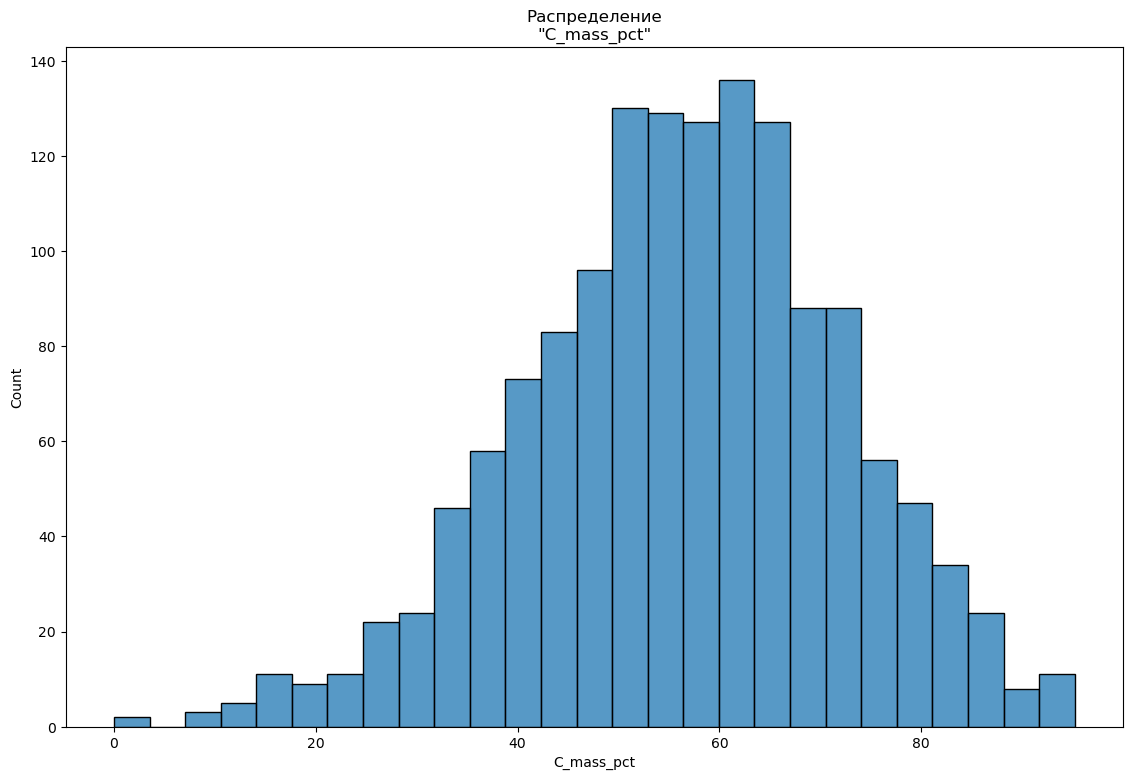

In [26]:
#отрисуем то распределение, котрое у нас получилось
plt.figure(figsize=(30,30))
plt.subplot(3,2,1)
sns.histplot(unique_df['C_mass_pct'])
plt.title(f'Распределение\n"{'C_mass_pct'}"')

In [27]:
#посчитаем выбросы, сначала просто считаю два квартиля, а потому беру 1,5 их раницы для отсекания выбросов, котрые нетипичны для нашей выборки 
q1=unique_df['C_mass_pct'].quantile(0.25)
q3=unique_df['C_mass_pct'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
outliers_iqr = unique_df[ (unique_df['C_mass_pct'] < lower) | (unique_df['C_mass_pct'] > upper)]

In [28]:
outliers_iqr

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,FDA_Approved,Source,Class,Brutto_Formula,Mollar_Mass,C_mass_pct
601,N=C(N)N.O=[N+]([O-])O,278.05,ethanol,CCO,0.003000,0.052430,-1.280418,Guanidine nitrate,506-93-4,10481.0,No,10.1016/j.fluid.2014.12.037,0,CH6N4O3,122.084,9.838308
625,CP(=O)(O)O,288.38,ethanol,CCO,0.412700,12.106503,1.083019,Methylphosphonic acid,993-13-5,13818.0,No,10.1016/j.fluid.2015.01.009,0,CH5O3P,96.022,12.508592
830,Brc1sc(Br)c(Br)c1Br,281.25,ethanol,CCO,0.001491,0.025928,-1.586234,"2,3,4,5-tetrabromothiophene",3958-03-0,77565.0,No,10.1016/j.jct.2012.06.005,0,C4Br4S,399.727,12.019203
1270,NC(N)=S,283.15,ethanol,CCO,0.018510,0.326510,-0.486103,Thiourea,62-56-6,2723790.0,No,10.1016/j.jct.2015.11.004,0,CH4N2S,76.124,15.778204
4195,NC(N)=[NH2+].[Cl-],278.15,ethanol,CCO,0.083160,1.580263,0.198729,Guanidine hydrochloride,NaN,5460839.0,No,10.1016/j.molliq.2021.116468,0,CH6ClN3,95.533,12.572619
5876,CS(N)(=O)=O,283.13,ethanol,CCO,0.026480,0.471325,-0.326680,Methanesulfonamide,3144-09-0,72879.0,No,10.1021/acs.jced.2c00012,0,CH5NO2S,95.123,12.626809
6269,[NH3+]O.[NH3+]O.[O-]n1nnnc1-c1nnnn1[O-],298.15,ethanol,CCO,0.000013,0.000230,-3.637962,"Dihydroxylammonium 5,5’-bistetrazole-1,1′-diol...",NaN,139051543.0,No,10.1021/acs.jced.3c00146,0,C2H8N10O4,236.152,10.172262
8030,Fc1c(I)c(F)c(I)c(F)c1I,290.15,ethanol,CCO,0.000570,0.009798,-2.008862,"1,3,5-trifluoro-2,4,6-triiodobenzene",84322-56-5,3852430.0,No,10.1021/acs.jced.9b00381,0,C6F3I3,509.772,14.136908
8042,Nc1nnn[nH]1,283.15,ethanol,CCO,0.000800,0.013862,-1.858186,5-aminotetrazole,4418-61-5,20467.0,No,10.1021/acs.jced.9b00385,0,CH3N5,85.070,14.118961
8741,ClP1(Cl)=NP(Cl)(Cl)=NP(Cl)(Cl)=N1,298.45,ethanol,CCO,0.010600,0.182531,-0.738664,Hexachlorocyclotriphosphazene,940-71-6,220225.0,No,10.1021/je1009812,0,Cl6N3P3,347.661,0.000000


Соответственно мы получили отдельный даатфрейм с выбросами: это те молекулы, которые содержат необычно малой и большой массвой долей угерода в молекуле. Напишем функцию, котрая нарисует нам все эти молекулы:

In [29]:
#Изначально я хотел накатить сюда Cairo, тогда можно было бы исолпользовать простую "MolToImage", чтобы проходится по столбцу со SMILES и отрисовывать каждую молекулу,
# но почему-то Cairo у меня сюда не встал, поэтому я использую другой подход:
import os #необходима для создания папки и в целом работы с файлами
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
output_dir='mol_pictures'
os.makedirs(output_dir, exist_ok =True) #собственно создаем директрию с названием mol_pictures, exist_ok =True отвечает за то, что если такая папка уже существует, то это нормально, это нужно, чтобы на первом этапе применения функции мы эту папку создали, а дальше у функции не возникало вопросов относительно того, что ей надо создать папку, котрая уже есть
def pic_from_smiles (smiles, idx, size=(100,100)):
    mol = Chem.MolFromSmiles(smiles) 
    filename=f'{idx}.svg' #это наше название файла
    path=os.path.join(output_dir, filename) #путь, который мы и будет передавать в столбец с путем к файлу
    drawer =rdMolDraw2D.MolDraw2DSVG(size[0],size[1]) #созаднеи пустого холтста
    drawer.DrawMolecule(mol) #отрисовка молекулы
    drawer.FinishDrawing() #бещ нео не работает
    svg=drawer.GetDrawingText() #возвращает строку с данными из SVG-файла, которые потом и запишем в столбик
    with open(path, 'w', encoding='utf-8') as p: #RDkit дает нам тест, котрые надо куда-то записать, чтобы он стал картинкой, соответственно его надо куда-то записать, открываем файл по пути "path", режим работы у нас w=writing, тип кодировки "utf-8"
        p.write(svg) #записываем туда наш тест
    return path
def add_svg_column(df, smiles_col="SMILES_Solute"): #другая функция для применения функции выше к датафрейму 
    df = df.copy()
    df['structure_svg'] = [pic_from_smiles(smiles, idx) for idx, smiles in df[smiles_col].items()]
    return df
outliers_iqr = add_svg_column(outliers_iqr, smiles_col="SMILES_Solute")

In [30]:
outliers_iqr

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,FDA_Approved,Source,Class,Brutto_Formula,Mollar_Mass,C_mass_pct,structure_svg
601,N=C(N)N.O=[N+]([O-])O,278.05,ethanol,CCO,0.003000,0.052430,-1.280418,Guanidine nitrate,506-93-4,10481.0,No,10.1016/j.fluid.2014.12.037,0,CH6N4O3,122.084,9.838308,mol_pictures/601.svg
625,CP(=O)(O)O,288.38,ethanol,CCO,0.412700,12.106503,1.083019,Methylphosphonic acid,993-13-5,13818.0,No,10.1016/j.fluid.2015.01.009,0,CH5O3P,96.022,12.508592,mol_pictures/625.svg
830,Brc1sc(Br)c(Br)c1Br,281.25,ethanol,CCO,0.001491,0.025928,-1.586234,"2,3,4,5-tetrabromothiophene",3958-03-0,77565.0,No,10.1016/j.jct.2012.06.005,0,C4Br4S,399.727,12.019203,mol_pictures/830.svg
1270,NC(N)=S,283.15,ethanol,CCO,0.018510,0.326510,-0.486103,Thiourea,62-56-6,2723790.0,No,10.1016/j.jct.2015.11.004,0,CH4N2S,76.124,15.778204,mol_pictures/1270.svg
4195,NC(N)=[NH2+].[Cl-],278.15,ethanol,CCO,0.083160,1.580263,0.198729,Guanidine hydrochloride,NaN,5460839.0,No,10.1016/j.molliq.2021.116468,0,CH6ClN3,95.533,12.572619,mol_pictures/4195.svg
5876,CS(N)(=O)=O,283.13,ethanol,CCO,0.026480,0.471325,-0.326680,Methanesulfonamide,3144-09-0,72879.0,No,10.1021/acs.jced.2c00012,0,CH5NO2S,95.123,12.626809,mol_pictures/5876.svg
6269,[NH3+]O.[NH3+]O.[O-]n1nnnc1-c1nnnn1[O-],298.15,ethanol,CCO,0.000013,0.000230,-3.637962,"Dihydroxylammonium 5,5’-bistetrazole-1,1′-diol...",NaN,139051543.0,No,10.1021/acs.jced.3c00146,0,C2H8N10O4,236.152,10.172262,mol_pictures/6269.svg
8030,Fc1c(I)c(F)c(I)c(F)c1I,290.15,ethanol,CCO,0.000570,0.009798,-2.008862,"1,3,5-trifluoro-2,4,6-triiodobenzene",84322-56-5,3852430.0,No,10.1021/acs.jced.9b00381,0,C6F3I3,509.772,14.136908,mol_pictures/8030.svg
8042,Nc1nnn[nH]1,283.15,ethanol,CCO,0.000800,0.013862,-1.858186,5-aminotetrazole,4418-61-5,20467.0,No,10.1021/acs.jced.9b00385,0,CH3N5,85.070,14.118961,mol_pictures/8042.svg
8741,ClP1(Cl)=NP(Cl)(Cl)=NP(Cl)(Cl)=N1,298.45,ethanol,CCO,0.010600,0.182531,-0.738664,Hexachlorocyclotriphosphazene,940-71-6,220225.0,No,10.1021/je1009812,0,Cl6N3P3,347.661,0.000000,mol_pictures/8741.svg


В результате в отдельной папке мы можем посмотреть все структуры молекул, которые были признаны выбросами. Можно заметить, что большинтво этих молекул - это либо какие-то соли, либо гетероциклы, либо структуры, богатые галогенами (это вполне логично: галогены обладают большой массой, в следствии чего массоваая доля углерода в них снижается). Я считаю такой набор молекул в "выбросах" вполне обоснованным, так как дейстаительно соль тетразола и полностью прогалаганированная ароматика - не самые стандартные субстраты в орагнике.

_ваши наблюдения здесь_

### Задача 2: Подготовка данных для обучения нейронной сети (3 балла)

По результатам предыдущей задачи выберите растворитель с наибольшим числом уникальных структур в *SMILES_Solute*. Для записей с этим растворителем проведите подготовку и разбиение данных:
 - Расчет и отбор признаков входных записей для обучения (если не сделано в задаче 1).
 - Фильтрацию выбросов по значению растворимости и температуры раствора. Подойдет и обычная квантильная фильтрация для экстремально высоких/низких значений растворимости (если в такой фильтрации нет необходимости - мотивируйте в выводах).
 - *Опционально*: Фильтрацию выбросов по структурам. Для этого вспомните обсуждения с занятий про применение алгоритмов машинного обучения без учителя в химии.
 - **Осмысленное** разбиение на обучающую и тестовую выборку. Если чувствуете себя уверенно с нейросетями, предусмотрите также и валидационную выборку для статистически-корректного подбора модели и чекпоинта обучения.
 - Проведите нормализацию входных признаков и целевого свойства. Не забудьте, что *Scaler* учится на обучающих данных, на тестовые он применяется уже обученным во избежание утечки данных.
 - *Опционально*: Подготовьте **DataLoader** для загрузки данных в нейронную сеть.

Решение и выводы должны отвечать как минимум на следующие вопросы:
 - Как быть с температурой? Какова экспериментально наблюдаемая зависимость растворимости от температуры в рамках одной структуры? Если мы не можем ее игнорировать, как учесть (явно или неявно) ее влияние в обучаемой модели?
 - Какими методами вы пользовались для отбора признаков и фильтрации записей/структур? Чем мотивирован этот выбор?
 - Какой смысл ваше разбиение имеет с точки зрения проверки обобщающей способности модели в *реальной* задаче? Задумайтесь в том числе о надежности и воспроизводимости данных в разных источниках.
 - Чем мотивирован выбранный размер батча в **DataLoader**? Если вы решили им не пользоваться, объясните, почему.

В 1 номере мы выйснили, что наиболшее количество уникальных записей в датафрейме у этанола. Соберем табличку с записями, в которых растворителем является этанол. 

In [31]:
the_most_popular_solvent_df=original_df[original_df['Solvent']==the_most_popular_solvent]
the_most_popular_solvent_df

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,FDA_Approved,Source
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.00060,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
1,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,314.65,ethanol,CCO,0.00120,0.020100,-1.696799,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
2,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,319.15,ethanol,CCO,0.00200,0.033356,-1.476824,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
3,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,322.15,ethanol,CCO,0.00500,0.083356,-1.079064,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
4,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,324.15,ethanol,CCO,0.01390,0.233286,-0.632111,Ethylene glycol monoeicosate,26158-80-5,538813.0,No,10.1007/bf00649573
...,...,...,...,...,...,...,...,...,...,...,...,...
10266,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,318.80,ethanol,CCO,0.00207,0.034540,-1.461680,Quercetin,117-39-5,5280343.0,No,10.1021/je9010757
10267,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,322.20,ethanol,CCO,0.00218,0.036238,-1.440831,Quercetin,117-39-5,5280343.0,No,10.1021/je9010757
10268,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,325.60,ethanol,CCO,0.00230,0.038089,-1.419199,Quercetin,117-39-5,5280343.0,No,10.1021/je9010757
10269,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,331.20,ethanol,CCO,0.00250,0.041143,-1.385701,Quercetin,117-39-5,5280343.0,No,10.1021/je9010757


Вот мы получили 10271 записей, в каждой из которых растворитель - это этанол (блин, класс), теперь надо выбрать какой-либо признак, чтобы предсказывать расвтримость на его основе. Я предлагаю отдельно посчитать молекулярные массы для каждой записи: это должно иметь смысл, ведь наиболее крупные молекулы как правило хуже растворимы. Изначально у меня была идея прдсказывать растворимость чисто по температуре, но потом я понял, что что это не самая лучшая идея, так как температура никак не описывает сами молекулы, она лишь говорит, при какой температуре проводили измерения. Так что я решил обратится опть к RDkit: в нем есть несколько инструментов, котрые помогут лучше описать молекулы: молярка/гидрофобность/полярная площадь (скольок полряных молекул доступно растворителю)/количество доноров и акцепторов водородных связей/количесвто вращающихся связей/число колец в молекуле/число ароматических колец в молекуле/количесвто sp3-гибризизованного угелерода от общего числа атомов углерода.

In [32]:
#Тогда:
def basic_discriptors(SMILES_Solute): #то есть эта функция просто берет на вход структуру смайсл и на вызод выдает нам словарь с описанием конерктной молекулы.
    mol=Chem.MolFromSmiles(SMILES_Solute)
    if mol is None:
        return None
    return{"MolWt": Descriptors.MolWt(mol),
        "MolLogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),                     
        "NumHDonors": Descriptors.NumHDonors(mol),
        "NumHAcceptors": Descriptors.NumHAcceptors(mol),
        "NumRotatableBonds": Descriptors.NumRotatableBonds(mol),
        "RingCount": Descriptors.RingCount(mol),
        "NumAromaticRings": Descriptors.NumAromaticRings(mol),
        "FractionCSP3": Descriptors.FractionCSP3(mol),}
#Теперь я просто соберу из данных словариков отдельный датафрейм и склею его по индексу с the_most_popular_solvent_df:
discriptors=the_most_popular_solvent_df['SMILES_Solute'].apply(basic_discriptors) #получаем серию словарей, с ней менее удобно рабооать, чем с списком словарей, так что надо будет сделать перевод
discriptors_df=pd.DataFrame(discriptors.tolist(), index=the_most_popular_solvent_df.index) #часть про индекс нужна, чтобы при склейке строчки никуда не уехали, и дисрипторы каждлой молекулы оказались правда в нужной нам стоке
the_most_popular_solvent_df=pd.concat([the_most_popular_solvent_df, discriptors_df], axis=1)#axis=1 нужен, чтобы склейка была горизональной, а не вертикальной
the_most_popular_solvent_df

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,...,Source,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,FractionCSP3
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.00060,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
1,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,314.65,ethanol,CCO,0.00120,0.020100,-1.696799,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
2,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,319.15,ethanol,CCO,0.00200,0.033356,-1.476824,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
3,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,322.15,ethanol,CCO,0.00500,0.083356,-1.079064,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
4,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,324.15,ethanol,CCO,0.01390,0.233286,-0.632111,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10266,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,318.80,ethanol,CCO,0.00207,0.034540,-1.461680,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10267,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,322.20,ethanol,CCO,0.00218,0.036238,-1.440831,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10268,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,325.60,ethanol,CCO,0.00230,0.038089,-1.419199,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10269,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,331.20,ethanol,CCO,0.00250,0.041143,-1.385701,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000


Все, все признаки расчитаны, теперь можно начинать фильтрацию выбросов, но для начала посмотрим исходное распределение температуры и расвтримости в нашей the_most_popular_solvent_df

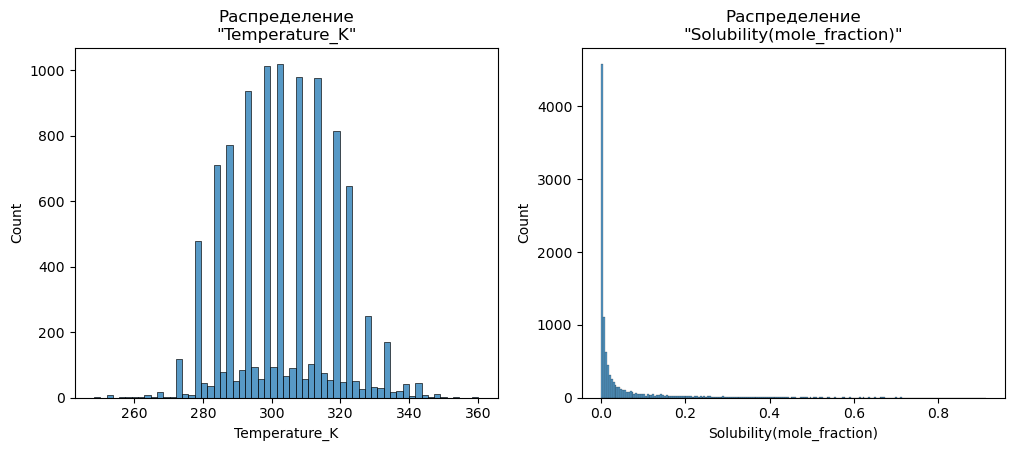

In [33]:
#я уже использовал этот код выше, когда строил распределение записей по источникам
plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
sns.histplot(the_most_popular_solvent_df['Temperature_K'])
plt.title(f'Распределение\n"{'Temperature_K'}"')
plt.subplot(2,2,2)
sns.histplot(the_most_popular_solvent_df['Solubility(mole_fraction)'])
plt.title(f'Распределение\n"{'Solubility(mole_fraction)'}"')
plt.show()


In [34]:
#что делать с температурой в целом понятно: у нас есть основные значения в диапазоне 270-330К, но есть и какие-то редкий значения вне этого диапзона, их логичнее просто отрезать
t_low, t_high = the_most_popular_solvent_df['Temperature_K'].quantile([0.01,0.99])
mask_t=the_most_popular_solvent_df['Temperature_K'].between(t_low, t_high) #тут я получаю серию булевых значений: то есть True6 если температура попадает между нашими квантилями, и False, если не попадает
df_clean=the_most_popular_solvent_df[mask_t].copy()# тут простт оставляю те записи, у котрыз True в mask_t
df_clean

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,...,Source,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,FractionCSP3
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.00060,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
1,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,314.65,ethanol,CCO,0.00120,0.020100,-1.696799,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
2,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,319.15,ethanol,CCO,0.00200,0.033356,-1.476824,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
3,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,322.15,ethanol,CCO,0.00500,0.083356,-1.079064,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
4,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,324.15,ethanol,CCO,0.01390,0.233286,-0.632111,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10266,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,318.80,ethanol,CCO,0.00207,0.034540,-1.461680,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10267,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,322.20,ethanol,CCO,0.00218,0.036238,-1.440831,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10268,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,325.60,ethanol,CCO,0.00230,0.038089,-1.419199,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10269,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,331.20,ethanol,CCO,0.00250,0.041143,-1.385701,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000


In [35]:
#Теперь будем работать с расвторимостью, а тоснее с ее десятичным логарифмом. В изначальном датафрейме у нас в столбцах с расвтримостями были пропуски, перепроверим это на уже почищенном датафрейме:
df_clean.isna().sum()

SMILES_Solute                  0
Temperature_K                  0
Solvent                        0
SMILES_Solvent                 0
Solubility(mole_fraction)      0
Solubility(mol/L)              0
LogS(mol/L)                    0
Compound_Name                  0
CAS                          624
PubChem_CID                  232
FDA_Approved                   0
Source                         0
MolWt                          0
MolLogP                        0
TPSA                           0
NumHDonors                     0
NumHAcceptors                  0
NumRotatableBonds              0
RingCount                      0
NumAromaticRings               0
FractionCSP3                   0
dtype: int64

Получается, что у нас нет пропусков в значениях растворимостях в нашем почищенном по парметру температуры датафрейме, так что мы сразу можем перейти к очистке от выбросов по ней. Так же я понял, что гораздо логичнее фильтровать уже по значению логарифма, там распределение больше походит на нормлаьное, а значит можно сделать буквально то же самое, что я делала при филрации по температуре.

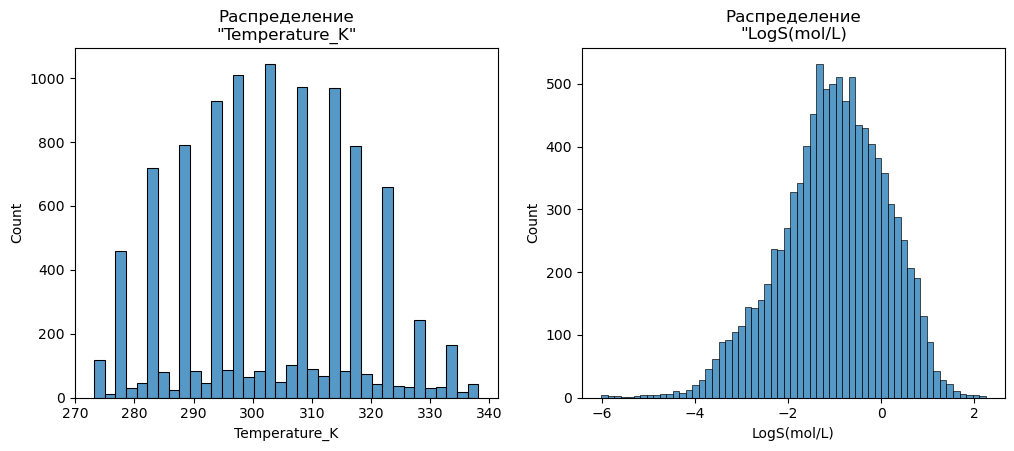

In [36]:
plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
sns.histplot(df_clean['Temperature_K'])
plt.title(f'Распределение\n"{'Temperature_K'}"')
plt.subplot(2,2,2)
sns.histplot(df_clean['LogS(mol/L)'])
plt.title(f'Распределение\n"{'LogS(mol/L)'}')
plt.show()

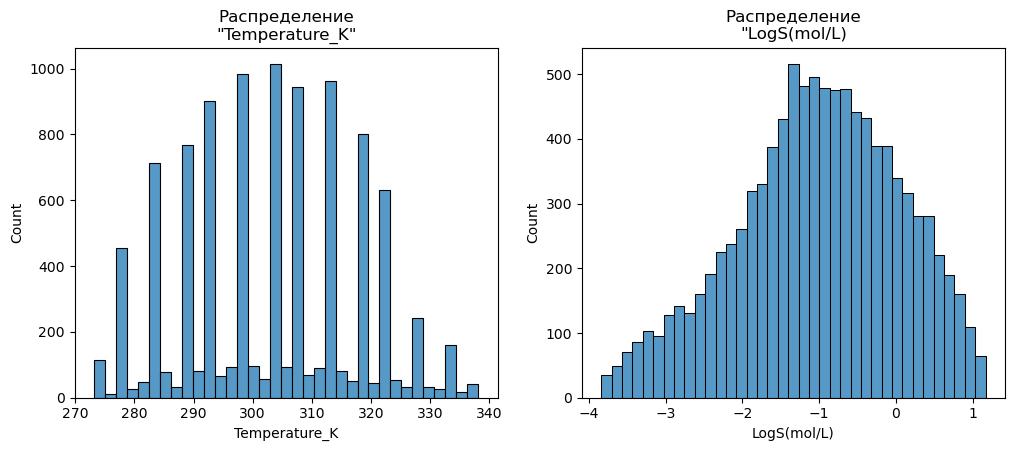

In [37]:
s_low, s_high = df_clean['LogS(mol/L)'].quantile([0.01, 0.99])
mask_S = df_clean['LogS(mol/L)'].between(s_low, s_high)
df_clean = df_clean[mask_S].copy()
plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
sns.histplot(df_clean['Temperature_K'])
plt.title(f'Распределение\n"{'Temperature_K'}"')
plt.subplot(2,2,2)
sns.histplot(df_clean['LogS(mol/L)'])
plt.title(f'Распределение\n"{'LogS(mol/L)'}')
plt.show()


Основная фильрация сделана (по температуре и расвтримости), осталорсь сделать фильрацию по структурам. Я решил реализовать эту фильтрацию довльно просто: я переведу все молекулки в отпечатки Моргана (это просто гораздо более емкое представление, чем кучу дескрипторов из RDkit) и выявлю аномалии с помощью алгоритма IsolationForest (он найдет для меня изолированные, то есть нетипичные точки, в нашем млучае молекулы)

In [38]:
from rdkit.Chem import AllChem #этот импорт нужен для перевода молекул в отпечатки Моргана
from sklearn.ensemble import IsolationForest #этот импорт нужен для выявления аномалий с помощью алгоритма IsolationForest
from sklearn.decomposition import PCA #этот импорт нужен для сжатия отпечатков Моргана (изначатльно его размерност= 2048 Бит, прит таких размерах методы IsolationForest становятся тяжелыми вычислительно, поэтому можно искуственно уменьшить размер, чтобы лес работал быстре)
morgan_fps = df_clean['SMILES_Solute'].apply(lambda s: AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, nBits=2048))
#morgan_fps=df_clean['SMILES_Solute'].apply(lambda s: AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, nBits=2048)) #сначала все молекулы по смайлс перевеодим в отпечатки Моргана
#я просто применяю к столбцу SMILES_Solute в датафрейме df_clean функцию AllChem.GetMorganFingerprintAsBitVect (получить отпечатки моргана как битовый вектор), которая переводит молекулы в отпечатки Моргана
# прдварительно смайлс переводится в молекулу (цифра 2 означает радиус окрестности атома в химическом графе, в нашем случае мы смотрим на 2 атома рядом с каждым))
# то есть morgan_fps - это просто списки из 0 и 1, которые теперь кодируют наши молекулы
print(morgan_fps)
X=np.array([np.frombuffer(fp.ToBitString().encode('utf-8'), 'u1') - ord('0') for fp in morgan_fps])#преобразование отпечатков в numpy-массив:
# fp.ToBitString() делает из массива строку типа "00110...1010", но np.frombuffer умеет работать тольок с байтами, поэтому надо сначала перевести строку в байты
# тогда уже np.frombuffer читает наши байты как числа и отнимает от них ord('0') - то есть 48, чтобы получить числа 0 и 1
# мне кажеься, что это очень круто
pca = PCA(n_components=20) #это не ренгено структурный анализ, а метод главных компонент (Principal Component Analysis), который позволяет сжать размерность наших данных, чтобы алгоритм IsolationForest работал быстрее
# на самом деле можно просто кодировать отпечатки Моргана в вектор меньшей размерности, но на разных сайтах типо https://www.kaggle.com/code/kumaraakshant/morgan-fingerprint-method используеют именно 2048Бит кодировку с последующим РСА
# это объект класса PCA из scikit‑learn, котрый говрит: переведи мои данные в 20-мерное пространство
X_pca = pca.fit_transform(X) # X - это как раз наши отпечатки Моргана, котрые мы переводим в 20-мерное представление
iso = IsolationForest(contamination=0.05, random_state=42) #собственно наша моделька, котрая работает на isolationforest: 5% значений считаем анамальными
labels = iso.fit_predict(X_pca) #предсказание  класса для каждой точки
mask_struct = labels == 1 #1=нормальная точка, -1=выброс, то есть мы просто создаем маску, как мы это уже делали для температуры илирасвтримости
df_struct_clean = df_clean[mask_struct].copy() #оставляем только нормальные точки

[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerator
[23:23:19] DEPRECATION WARNING: please use MorganGenerat

0        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...
1        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...
2        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...
3        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...
4        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...
                               ...                        
10266    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
10267    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
10268    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
10269    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
10270    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
Name: SMILES_Solute, Length: 9917, dtype: object


Вообще еще можно было бы классно визулизировать разделение структур на нормальные и аномальные, но этим может быть я займусь позже


In [39]:
df_struct_clean

,SMILES_Solute,Temperature_K,Solvent,SMILES_Solvent,Solubility(mole_fraction),Solubility(mol/L),LogS(mol/L),Compound_Name,CAS,PubChem_CID,...,Source,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,FractionCSP3
0,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,311.25,ethanol,CCO,0.00060,0.010083,-1.996419,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
1,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,314.65,ethanol,CCO,0.00120,0.020100,-1.696799,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
2,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,319.15,ethanol,CCO,0.00200,0.033356,-1.476824,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
3,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,322.15,ethanol,CCO,0.00500,0.083356,-1.079064,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
4,CCCCCCCCCCCCCCCCCCCC(=O)OCCO,324.15,ethanol,CCO,0.01390,0.233286,-0.632111,Ethylene glycol monoeicosate,26158-80-5,538813.0,...,10.1007/bf00649573,356.591,6.5636,46.53,1,3,20,0,0,0.954545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10266,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,318.80,ethanol,CCO,0.00207,0.034540,-1.461680,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10267,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,322.20,ethanol,CCO,0.00218,0.036238,-1.440831,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10268,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,325.60,ethanol,CCO,0.00230,0.038089,-1.419199,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000
10269,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,331.20,ethanol,CCO,0.00250,0.041143,-1.385701,Quercetin,117-39-5,5280343.0,...,10.1021/je9010757,302.238,1.9880,131.36,5,7,1,3,3,0.000000


Структур стало меньше, значит какие-то аномальные молекулы точно выбросились.

Теперь надо решить вопрос с "осмысленным разбиением молекул на тестовую и тренировочную выборку". Как я себе это понимаю: у меня в датафрейме присутствуют записи для одной и той же структуры, которые отличаются температурой раствора, и я не должен допустить, чтобы одна и та же молекула, но при слегка разных температурах попала и в тренировчную, и в тестовую выборку, потому что наша модулька тогда сможет по косвенным признакам, которые мы в нее передаем (количество колец в структре, молярная масса, количество доноров водородной связи и так далее), понять, что это та же молекула, на котрой она училась, а это убьет ввесь смысл разделенния на тренировочную и тестовую выборку.

In [40]:
#по описанным выше причинам обычный train_test_split нам не подойдет, то есть мне надо озаботиться о том, чтобы какой-нибудь Ethylene glycol monoeicosate весь целиком попал в тест
#что я предлагю сделать: взять уникальные smiles, разбить их по рандому на выборки и подтянуть к ним уже все записи, относящие к этому smiles
# дальше надо было решить, скольок выборок мне стоит делать (тренировка+тест или тренировка+валидация+тест), с учетом того, что у меня без малого 10000 строк, я вполне могу себе позволить 3 выборки
# для этого мне потребуется GroupShuffleSplit (нашел его на https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
# в чем его фишка: Provides randomized train/test indices to split data according to a third-party provided group. 
from sklearn.model_selection import GroupShuffleSplit
groups = df_struct_clean['SMILES_Solute']#определяем группы по структуре, потом мы передалим их как раз GroupShuffleSplit, чтобы он делил нашу выборку на трейн и тест
gss = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42) #сначала train+temp (где temp потом разделим на val/test), делаем всего 1 разбиение n_splits=1, размер теста -20%, размер тренировочной выборки- 80%
train_idx, temp_idx = next(gss.split(df_struct_clean, groups=groups)) #получаем два набора индексов: одни пойдет в трейн, другие в темп
#собираем 2 отдельных датафрейма (вытягиваем записи по индексам), тренировка и темп (в дальнейшем разобьем еще на валидацию и тест)
train_df = df_struct_clean.iloc[train_idx].copy()
temp_df  = df_struct_clean.iloc[temp_idx].copy()
groups_temp = temp_df['SMILES_Solute'] #теперь делим temp на val и test, снова по группам
gss_val = GroupShuffleSplit(test_size=0.5, n_splits=1, random_state=42) #разбиваем те 20 процентов темпа еще попалам 
val_idx, test_idx = next(gss_val.split(temp_df, groups=groups_temp))
val_df  = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy() 

Итого:
У нас есть три датафрейма:
train_df - датафрейм для тренировки (~80%)
val_df - датафрейм для валидации (~10%)
test_df - датафрейм для теста (~10%)


Тперь необходимо провести нормализацию данных: это нужно сделать по-умному, пока делал этот пункт, обращался к статье https://habr.com/ru/articles/527334/. Но в моем случае уже хорошо 

In [41]:
#посмтрим на описание наших фичей сейчас
feature_cols=["MolWt", "MolLogP", "TPSA","NumHDonors", "NumHAcceptors","NumRotatableBonds","RingCount", "NumAromaticRings","FractionCSP3","Temperature_K"]
df_struct_clean[feature_cols + ['LogS(mol/L)']].describe()
#и тут уже заметиим, что надо сделать дполнительную филтрацию по массе: среднее значение - 265, а максимальное - 1178, это слишком много
low_mw, high_mw = df_struct_clean['MolWt'].quantile([0.01, 0.99])
mask_mw = df_struct_clean['MolWt'].between(low_mw, high_mw)
df_struct_clean = df_struct_clean[mask_mw].copy()

In [42]:
#еще раз смотрим на то,что стаало с нашим датафреймом
df_struct_clean[feature_cols + ['LogS(mol/L)']].describe()

,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,FractionCSP3,Temperature_K,LogS(mol/L)
count,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000,9251.000000
mean,252.155062,1.759056,70.226008,1.448600,3.558426,2.944006,1.896227,1.344503,0.288503,302.876902,-0.967244
std,120.382198,2.281158,40.898620,1.359424,2.256550,2.956130,1.338510,1.050975,0.288397,14.579765,1.054485
min,84.078000,-8.995600,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,273.150000,-3.838140
25%,165.170000,0.506500,43.780000,1.000000,2.000000,1.000000,1.000000,1.000000,0.000000,293.150000,-1.630917
50%,215.249000,1.601420,65.180000,1.000000,3.000000,2.000000,2.000000,1.000000,0.214286,303.150000,-0.905587
75%,310.931000,3.100900,86.740000,2.000000,5.000000,4.000000,3.000000,2.000000,0.500000,313.150000,-0.186985
max,821.141000,12.312600,336.680000,10.000000,18.000000,22.000000,10.000000,10.000000,1.000000,338.150000,1.169054


Теперь стало лучше, можем нормализовать:

In [43]:
from sklearn.preprocessing import StandardScaler
target_col = "LogS(mol/L)"  #таргетная колонка, то, что предсказываем
#X - мтарица входных значений, то есть то, что мы передаем в модель
X_train=train_df[feature_cols].values #я просто создаю массив, вытягивая из нашего тенировочнорго/валидационного или тестового датафрейма фичи (то, что закину потом в нейросеть)
X_val=val_df[feature_cols].values
X_test=test_df[feature_cols].values
# то, что хотим предсказать 
#reshape нужен, чтобы первести вектор из N-мерного вектора в двухмерных массив (N,1)
y_train=train_df[target_col].values.reshape(-1,1) # -1 говорит подставить стольок строк, скольок нужно, в нашем случае это будет количество записей в train_df
#1 говорит, что число столбцов =1
print(train_df[target_col].values)
print(y_train)
y_val=val_df[target_col].values.reshape(-1,1)
y_test=test_df[target_col].values.reshape(-1,1)
#нормализация для входных данных, мы 100 раз делали это на парах
x_scaler=StandardScaler() #это объект, котрый умеет стандартизировать признаки 
X_train_scaled=x_scaler.fit_transform(X_train) #применяем этот скейлер ко всем нашим датафреймам
X_val_scaled=x_scaler.transform(X_val)
X_test_scaled=x_scaler.transform(X_test)
#аналогично для таргетного значения
y_scaler=StandardScaler()
y_train_scaled=y_scaler.fit_transform(y_train)
y_val_scaled=y_scaler.transform(y_val)
y_test_scaled=y_scaler.transform(y_test)

[-1.99641909 -1.69679918 -1.47682386 ... -1.41919943 -1.38570124
 -1.37838595]
[[-1.99641909]
 [-1.69679918]
 [-1.47682386]
 ...
 [-1.41919943]
 [-1.38570124]
 [-1.37838595]]


_ваши наблюдения здесь_

In [44]:
#нормализация проведена, надо проверить, что она дейсвтиельно проведена нормально, и что это имело какой-то смысл
#сделаю позже

Последнее, что еще надо сдедать - это подготовить DataLoader для загрузки данных в нейронку. У меня по факту есть 3 части: тренировка, валидация и тест, для каждого из них мне нужно создать свою загрузчик.

In [45]:
import torch 
from torch.utils.data import TensorDataset, DataLoader
#выбираем устойство, на котром будем рабоать
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f'Device - {device}')
#нам нужно 3 отдельных загрузчика
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32, device=device) #тут мы переводим numpy.ndarray в тензор торча, потому что именно по ним считаются градиенты и обнвляются веса модель
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32, device=device) #аналогично для того, что нам нужно плучить на выходе. Отдельно я указаываю тип данных, потому что сам торч иногда по умолчанию берет float64, а параметры можели в торче автоматически float 32
train_dataset = TensorDataset(X_train_t, y_train_t) #собираем общий датасет из двух частей трейна
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) #DataLoader делает из датафрейма итератор батчей: параметр shuffle=True отвечает за пременшивание, размер батча выбран тоаким, просто потому он разумный: это позволит нам делать примерно 122 шагов за эпоху
#все абсолютно также для валидации
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32, device=device)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32, device=device)
val_dataset = TensorDataset(X_val_t, y_val_t)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
#все абсолютно также для теста
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32, device=device)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32, device=device)
test_dataset = TensorDataset(X_test_t, y_test_t)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Device - mps


- Как быть с температурой? Какова экспериментально наблюдаемая зависимость растворимости от температуры в рамках одной структуры? Если мы не можем ее игнорировать, как учесть (явно или неявно) ее влияние в обучаемой модели?

Для ответы на вопросы мне необходимос сделать еще несколько вещей: во-первых, я хочу посмтроить график зависимости расвтримости от температуры для 4 структур. это позвоит отвтеить на первый вопрос.

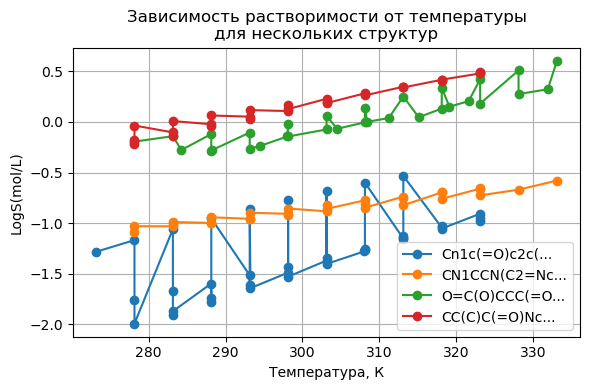

In [46]:
import matplotlib.pyplot as plt
import pandas as pd
#напишем функцию, которая выводит зависимость растворимости от температуры для рандомныз 4 молекул, для которрых есть более чем 10 записей
def plot_solubility_vs_temp(df, n_molecules=4, smiles_col='SMILES_Solute', temp_col='Temperature', target_col='LogS(mol/L)'):
    #Находим SMILES, для которых есть 10 и более измерений
    counts = df[smiles_col].value_counts()
    smiles_multiT = counts[counts >= 10].index.tolist()
    # 2. Берём первые n_molecules таких структур (можно выбрать случайно)
    selected_smiles = smiles_multiT[:n_molecules]#это просто срез: берем первые 4 молекулы
    #делаем полотно для графика
    plt.figure(figsize=(6, 4))
    for smi in selected_smiles: #теперь мы берем каждую из выбранных молекул
        sub = df[df[smiles_col] == smi].copy() #фильруем исходный датафрейм и оставляем там только молекулы с тем смайлсом, с котрым конерктно сейчас работаем, ествественно делаем копию, чтобы не затронуть первоначальный датафрейм
        #в итоге sub -это просто маленький датафрейм, который мы дальше сортируем по температуре
        sub = sub.sort_values(temp_col)
        plt.plot(sub[temp_col], sub[target_col], #сначала задаем икс и y (что по каким осям)
                 marker='o', linestyle='-', #задаем то, как будем отрисовыватт график, то есть мои точки - это шарики, котрые соединены линией
                 label=smi[:12] + '...' if len(smi) > 12 else smi) #это подпись к легенде, берем первые 12 символов каждой структры, чтобы она не занимала весь график
    plt.xlabel('Температура, К')
    plt.ylabel(f'{target_col}')
    plt.title('Зависимость растворимости от температуры\nдля нескольких структур')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
plot_solubility_vs_temp(df_struct_clean, n_molecules=4, smiles_col='SMILES_Solute', temp_col='Temperature_K', target_col='LogS(mol/L)')

Очень лочгино, что при росте температуры у нас растет растворимость наших молекул: мне кажется, что это логичный общий тренд. Как учитывать температуру? Я просто буду подавать ее на вход в нейросеть, то етсь это будет еще одним дискриптором.

- Какими методами вы пользовались для отбора признаков и фильтрации записей/структур? Чем мотивирован этот выбор?

В качестве входных признаков использовались численные дескрипторы молекул, полученный из RDkit и температура раствора. Отдельного автоматического отбора признаков (по дисперсии или корреляции) я не проводил: исходный набор дескрипторов сформирован на основе химической интерпретируемости, поэтому мне показалось, что каждый признак потенциально информативен для моделирования растворимости. Однако, фильтрация данных выполнялась на уровне записей (по квантилям): для массы, растворимости и температуры применялась квантильная очистка, при которой наблюдения с экстремальными значениями за пределами выбранных квантилей удалялись

 - Какой смысл ваше разбиение имеет с точки зрения проверки обобщающей способности модели в *реальной* задаче? Задумайтесь в том числе о надежности и воспроизводимости данных в разных источниках.

Я уже писал об этом выше: когда я делил свой датафрейм на 3 выборки я следил за тем, чтобы  одна и та же молекула не поапада и в обучающую и в тестовую выборку, потму что это как раз бы убило бы полезность нашей модел. Мое разбиение имитирует реальную постановку задачи, в которой модель должна предсказывать растворимость новых молекул, а не просто интерполировать по тем же структурам в немного других условиях.

- Чем мотивирован выбранный размер батча в **DataLoader**? Если вы решили им не пользоваться, объясните, почему.

При обучении нейросетевой модели данные подавались через DataLoader с размером батча 32. На самом деле тут нет какого-то универсаьного ответа на вопрос, я выбрал именно такой батч, потму что у меня не очень много данных, и такой размер мне показался оптимальным: он достаточно мал, чтобы сохранять стохастичность градиента и работать в режиме mini‑batch SGD, что даёт лёгкий регуляризующий эффект и обычно улучшает обобщающую способность по сравнению с очень большими батчами

## Задача 3: Построение и тестирование модели регрессии. (4 балла)
Постройте и обучите модель предсказания растворимости молекулы в выбранном в предыдущем пункте растворителе при помощи выбранной архитектуры нейронных сетей. Для ответа на следующие вопросы вам сильно поможет наличие holdout-валидации и вспомогательные графики (например, график обучения нейронной сети, actual vs predicted и тд). 

Решение и выводы должны отвечать как минимум на следующие вопросы:
 - Какую архитектуру нейронной сети вы выбрали? Чем мотивирован ваш выбор?
 - Каковы на ваш взгляд основные недостатки выбранного подхода? Что позволило бы увеличить качество предсказания?
 - Каковы ограничения построенной модели? В каких условиях и при каких входных данны она не способна будет качественно работать?
 - *Если температура была выбрана в качестве одного из признаков* - во всем ли диапазоне температур модель одинаково хорошо справляется с предсказаниями? В чем причина?

*Примечание.* Данную задачу можно решить вообще не используя нейронную сеть. Тем не менее, отсутствие самого теста работоспособности нейронной сети для поставленной задачи приведет к понижению оценки за задачу на 1 балл.

In [47]:
from torch import nn #достаем класс нейронной сети из торча
import torch.optim as optim
#создадим модель, я старался сохранить архитерктуру, как мы писали на паре
target = ['LogS(mol/L)'] #собственно у нас есть 1 таргет
target_dim = len(target) #размерность выхожного пространства, в моем случае 1
input_dim = X_train_t.shape[1] #это просто число входных признаков, в моем случае
#сама модель, создана как объект model
# изначальноя написал однослойную нейронную сеть, но она прм совсем не вывозила сравнение даже с простой линейно регрессией, так что пришлось переписывать ее на двухслойную
model = nn.Sequential(
    nn.Linear(input_dim, 32), #этот параметр говорит моей моделе: бери входной тензор и последовательно прогоняю через мои слои. Еще я понизил количесвто параметров во внутреннем слое, их было изначатльно 64, но там я столкнулся с переобученим, теперь их 32
    nn.ReLU(), #это функция активации, изначально я использовал Sigmoid, но Релу показал лучшие результаты
    nn.Linear(32, target_dim) #это еще один линейгый слой, он принимает на вход вектор длинно 32, и выдает только целевое значение (таргет)
).to(device)
print(f'Архитектура модели:\n{model}')

Архитектура модели:
Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
)


In [48]:
print(input_dim) #логично: 9 дискрипторов+температрура

10


In [49]:
criterion = nn.MSELoss() #это функция потерь, в нашем случае мы псчитаем среднеувадаратичную ошибку
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4) #объект, который знает, как менять веса модели, чтобы уменьшать loss. Adam - то адаптивный градиентный спуск, сам подбирает шаг для кажлого параметра
# lr - learning rate, чем больше, тем быстрее будем двигаться к минимому
num_epochs = 300#количесвто эпох, сколько раз прохожусь по всей тренировочной выборке
patience = 50  # сколько эпох ждать улучшения val loss до остановки
train_loss_history = [] #сюда добавляю на каждом этапе средний train_loss, потмо можно будет посмтроить графики
val_loss_history = []
#мне так же пришлось добавить механизм сохранения лучшей модели, ведь до этого я прокатывал какое-то количесвто эпох и брал просто последнюю модель из всех6 даже если она уже кривая и косая,
#сейчас же я буду на каждом этапе считать epoch_val_loss, и если val loss улучшился, то сохраняюего в  best_state_dict и обновляю best_val_loss
best_val_loss = float('inf')
best_state_dict = None #это прсото словарик с весами лучшей на данный момент модели (ну в самом начале модели нет, значит ставлю None)
epochs_without_improvement = 0 #счетчик количества эпох без улучшения

In [50]:
#этот цикл по эпохам, будет повторять наше обучение столько арз, сколько у нас эпох
for epoch in range(num_epochs):
    model.train() #включаем режим обучения
    #счетчики для подсчёта среднего train loss за эпоху
    running_train_loss = 0.0 
    num_train_batches = 0
    #идем по батчам из trainloader 
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad() #обнуляем старые градиенты, чтобы они не суммировались с новыми
        outputs = model(X_batch) #модель выдаёт предсказания для этого батча
        loss = criterion(outputs, y_batch) #считаем MSE по этосу батчу 
        loss.backward() #вычисляем градиенты
        optimizer.step() #обновляем веса модели
        running_train_loss += loss.item() #копим значение loss для батча (в виде обычного числа)
        num_train_batches += 1 #считаем количество батчей
    epoch_train_loss = running_train_loss / num_train_batches #средний train loss за эпоху
    train_loss_history.append(epoch_train_loss) #добавляем в предварительно созданный массив это среднее
    #Валидация
    model.eval() # Включаем режим оценки (отключает dropout, batchnorm ...)
    running_val_loss = 0.0
    num_val_batches = 0
    with torch.inference_mode(): #  Временно отключает вычисление и хранение градиентов
        for X_batch_val, y_batch_val in val_loader: #это буквально аналогично тому, что было для тренировки, только у нас нет обновления весов, мы тольок меряем уже 
            val_outputs = model(X_batch_val)
            val_loss = criterion(val_outputs, y_batch_val)
            running_val_loss += val_loss.item()
            num_val_batches += 1
    epoch_val_loss = running_val_loss / num_val_batches
    val_loss_history.append(epoch_val_loss)
    #это и есть механизм ранней остановки, если потеря настоящей модкли лучше, чем то, что мы сохралили до этогт в лучшкю модель, то я перезаписываю лучшую потерю
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_state_dict = model.state_dict()
        epochs_without_improvement = 0 # так как улучшение произошло, зануляю переменную количесва эпох без улучшения
    else:
        epochs_without_improvement += 1 #иначе прибавляю еще одну эпоху к числе тех, в котрых не было улучшения
#выводим данные по обучению, то есть прсото вывожу данные о потери в настоящий момент
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Val Loss: {epoch_val_loss:.4f}"
        )
    #елси количесвто эпох без улучшения потери превысило "терпение", останавливаю обучение
    if epochs_without_improvement >= patience:
        print(f"Early stopping on epoch {epoch+1}. Best Val Loss: {best_val_loss:.4f}")
        break
if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
    print(f"Loaded best model with Val Loss = {best_val_loss:.4f}")


Epoch [50/300] Train Loss: 0.4594 Val Loss: 0.7305
Early stopping on epoch 57. Best Val Loss: 0.6650
Loaded best model with Val Loss = 0.6650


In [51]:
#оценка обученной модели на тесте
model.eval() #опять режим оценки
test_loss = 0.0
num_test_batches = 0
with torch.inference_mode(): #проход по тестовым батчам без градиента, как у нас это уже было на валидации
    for X_batch_test, y_batch_test in test_loader:
        test_outputs = model(X_batch_test)
        batch_test_loss = criterion(test_outputs, y_batch_test) # насколько предсказанная растворимость отличается от истинной
        test_loss += batch_test_loss.item()
        num_test_batches += 1
#расчет и вывод среднего MSE по тесту
avg_test_loss = test_loss / num_test_batches
print(f"Test MSE: {avg_test_loss:.4f}")

Test MSE: 0.7376


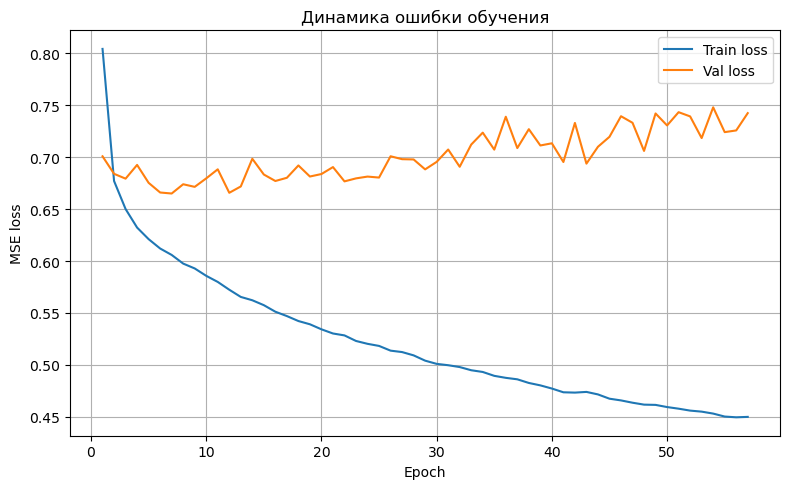

In [52]:
#Визуаллизация
epochs = np.arange(1, len(train_loss_history) + 1) # массив номеров эпох
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss_history, label='Train loss')
plt.plot(epochs, val_loss_history,   label='Val loss')
#называю оси
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.title('Динамика ошибки обучения')
plt.legend()
plt.grid(True) #включил сетку
plt.tight_layout()
plt.show()

Теперь стоит как-то прокоментировать этот график: ив видим, что train loss монотонно падает от 0,78 до 0,45, соотвественно модель учится общему тренду на данных.  С валидацией чуть сложнее, в начале ошибка на валидации падает (что логично), улучшение на трейне приводит к улучшению и на валидации, потом ошибка на валидации выходит на плато (0,6-0,62), а дальше судя по всему модель начинает подтсавиваться под шумы и особенности трейна, что в свою очередь уже не улучшает показатели на валидации, под конец ошибка на валидации начинает заметно расти к ~0,65, то есть улучшения долго не просиходит, и мы останавливаем обучение. Это иллюстрирует, зачем нам ранняя остановка, елси бы я просто брал самую последнюю модуль из всех, я бы вероятнее всего получил большую среднюю ошибку.

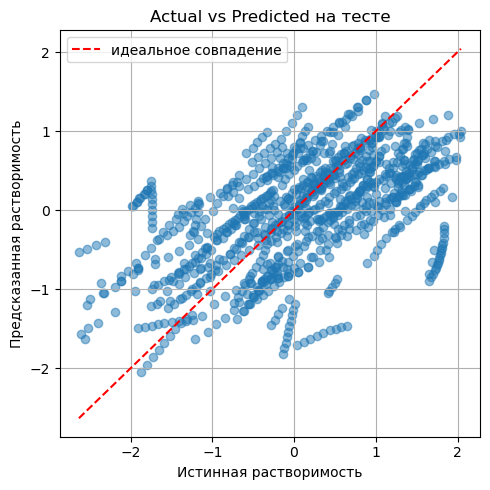

In [53]:
#Визуализаия  Actual vs Predicted на тесте:
model.eval() # мы как бы заново все тестовые объекты одним тензором прогоняем через модуль, чтобы получить наши предсказания 
with torch.inference_mode():
    y_test_pred = model(X_test_t).cpu().numpy().ravel() #получаем прдсказанные целевые значения
y_test_true = y_test_scaled.ravel()  #ravel делает таргет вектором той же длины, что и предсказанное значение
#Отрисовка
plt.figure(figsize=(5, 5))
plt.scatter(y_test_true, y_test_pred, alpha=0.5) #каждая точка - один объект из теста, соотвественно, елси предсказанное и реально значения совпадают, точка будет лежать на прямой y=x
plt.plot([y_test_true.min(), y_test_true.max()],
         [y_test_true.min(), y_test_true.max()],
         'r--', label='идеальное совпадение')
#называем оси
plt.xlabel('Истинная растворимость')
plt.ylabel('Предсказанная растворимость')
plt.title('Actual vs Predicted на тесте')
plt.legend()
plt.grid(True) # орять отрисовываю сетку
plt.tight_layout()
plt.show()

По графику видно, что в целом модель корректно улавливает тренд (облако вытянуто вдоль диагонали), но ошибки заметные, особенно на хвостах

In [54]:
#в самом конце я хочу сравниить прдсказания нейронной сети с простой линейной регресии
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
lin_reg = LinearRegression()
#обучаем линейню регрессию
lin_reg.fit(X_train_scaled, y_train_scaled)
#делаем прдсказания линейной регрессией
y_test_pred_lin = lin_reg.predict(X_test_scaled)
#ну и выводим метрики
mse_lin = mean_squared_error(y_test_scaled, y_test_pred_lin)
print(f"Linear Regression Test MSE: {mse_lin:.4f}")

Linear Regression Test MSE: 0.7968


Соответсвенно наша модель предсказывает расвторимость лучше, чем то делает линейная регрессия (нейронка - Test MSE: 0.7318; Linear Regression Test MSE: 0.7500), ну и слава богу

_ваши наблюдения здесь_

- Какую архитектуру нейронной сети вы выбрали? Чем мотивирован ваш выбор?

В качестве модели регрессии использовалась простая полносвязная нейронная сеть (MLP), построенная в виде последовательности из двух линейных слоёв с одной скрытой нелинейностью. Входной слой имеет размерность, равную числу используемых признаков (RDKit‑дескрипторы MolWt, MolLogP, TPSA, NumHDonors, NumHAcceptors, NumRotatableBonds, RingCount, NumAromaticRings, FractionCSP3 + температура), скрытый слой содержит 32 нейрона с активацией ReLU, выходной слой — один нейрон без активации, предсказывающий значение растворимости. На саммом деле я попробовал несколько архитектур: двухслойные, испольтзовал другие функции автовации, но они все очень быстро сваливались в переобучение, так что я остановился на довольно простом и работющем варианте, хоть мне и пришлось даже в этом случае: 1) сократить количесвто эпох 2) добавить функция ранеей остановики

 - Каковы на ваш взгляд основные недостатки выбранного подхода? Что позволило бы увеличить качество предсказания?
 
 Основные недостатки моего подхода связаны с тем, что модель опирается на небольшой набор заранее выбранных RDKit‑дескрипторов и температуру, а значит может упускать важные аспекты структуры и взаимодействий солют–солвен. Сама нейросеть представляет собой довольно простую однослойную MLP с 32 нейронами, чего достаточно для базовой нелинейности, но недостаточно для очень сложных зависимостей, особенно при ограниченном размере и разнообразии датасета, из‑за чего качество на молекулах, сильно отличающихся от обучающих, заметно падает (это ксати еще и к вопросу о применимости моей нейронки на других молекулах). Увеличить качество предсказаний потенциально позволили бы более богатые представления молекул (расширенный набор дескрипторов, 3D‑характеристики или переход к графовым/SMILES‑моделям), аккуратно углублённая архитектура с регуляризацией и систематическим подбором гиперпараметров, а также расширение обучающей выборки или использование предварительно обученных моделей с дообучением на данной задаче.

- Каковы ограничения построенной модели? В каких условиях и при каких входных данны она не способна будет качественно работать?

Модель надёжна только для молекул и температур, похожих на те, что были в обучающем наборе; для сильно других структур, классов соединений или экстремальных температур она начинает экстраполировать и может давать большие ошибки. Кроме того, если новые данные получены другими экспериментальными методиками и имеют другой систематический сдвиг или шум, качество предсказаний также ухудшится.

 - *Если температура была выбрана в качестве одного из признаков* - во всем ли диапазоне температур модель одинаково хорошо справляется с предсказаниями? В чем причина?

 Для ответа на этот вопрос мне так же надо еще немного написать код. Чисто интуитивно кажется, что конечно не во всем диапазоне модель будет рабоать одинакого хорошо, это связано с тем, что просто не все температуры одинакого хорошо представлены в нашем датафрейме, а значит, ниболее редкие температуры будут прдесказываться хуже, потму что можель просто не видела досточно примеров таких температур на трейне, но это все можно проверить, пострроив распредление ошибок по температурам. Итак:

In [55]:
model.eval() #берем нашу модель (она уже лучшая  модель так как до этого я сделал model.load_state_dict(best_state_dict)), переводим ее опять в режим оценки
with torch.no_grad(): #не считаем не храним градиенты
    y_pred_test_scaled = model(torch.tensor(X_test_scaled, dtype=torch.float32).to(device)) #превращаем массиы в тензор, переводим его туда же, где лежит модель
    y_pred_test_scaled = y_pred_test_scaled.cpu().numpy() #получаю предсказание модели на всех тестовый объектах и возвращаю их назад в NumPy
y_test = y_scaler.inverse_transform(y_test_scaled) # переводим настоящие значения таргета на тесте в масштабированную шкау, чтобы можно было сравнивать
y_pred_test = y_scaler.inverse_transform(y_pred_test_scaled) #переводим и предсказанные значения тоже в ту же шкалу
errors = y_pred_test.flatten() - y_test.flatten()  #flatten риводит оба массива к одномерному виду, чтобы было удобно вычитат, соответственно послет этого считаем ошибки
abs_errors = np.abs(errors)  #берем модуль от ошибки                          
temps_test = test_df["Temperature_K"].values #это вектор температур, чтобы ошибку модели связать с конеткноц температурой              

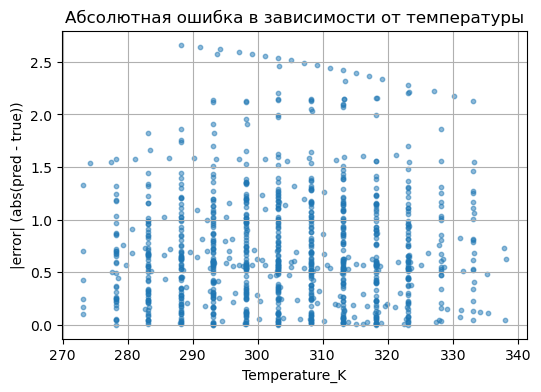

In [56]:
#Строим график
plt.figure(figsize=(6, 4))
plt.scatter(temps_test, abs_errors, alpha=0.5, s=10)
plt.xlabel("Temperature_K")
plt.ylabel("|error| (abs(pred - true))")
plt.title("Абсолютная ошибка в зависимости от температуры")
plt.grid(True)
plt.show()

Ну собстенно это подтверждает то, что я сказал: В области типичных температур (примерно 295–315 K), которые наиболее представлены в данных, разброс ошибок сравнительно небольшой, тогда как на краях диапазона, где наблюдений мало, встречаются отдельные более крупные ошибки. Это согласуется с тем, что нейросеть обучалась на неравномерном распределении температур

# Проектная работа 1. Расширение пространства признаков и fine-tuning нейронных сетей.

**ВАЖНО:** Перед началом работы над проектом в рамках предыдущей задачи вам **необходимо** учитывать температуру в качестве входных данных - иначе вам может не хватить данных для тестирования модели.

В рамках данного проекта предлагается углубиться в глубокое обучение и использовать его ключевую особенность - самостоятельное формирование признакового пространства и гибкость процедуры обучения/дообучения. Проект поделен на две части, показывающие два возможных направления расширения применимости модели - фичуризация растворителя и дообучение. 

**ВЫПОЛНЕНИЕ ОБЕИХ ЧАСТЕЙ ПРОЕКТА НЕ ЯВЛЯЕТСЯ ОБЯЗАТЕЛЬНЫМ ДЛЯ ЕГО ЗАЧЁТА.**
Выполнение обеих частей проекта позволяет получить максимальный балл (10) и до двух дополнительных баллов в копилку (при расчете финальной оценки их можно будет добавить к результатам предыдущих заданий) - дополнительные баллы присуждаются за блестящее выполнение обоих путей исследования и качество финального анализа.

В качестве цели исследования мы рассматриваем качество предсказания растворимости в существенно менее заполненных растворителях - в **метаноле** и в **воде**. Именно на эти две метрики вам предстоит ориентироваться при анализе результатов и подборе пути решения.

## Путь 1. Использование признаков растворителей (максимум - 7 баллов)
Выберите растворители, подходящие, на ваш взгляд, для обучения более полной модели предсказания растворимостей. Фичуризуйте их (можно воспользоваться категориальными признаками на основе колонки *'Solvent'* или предложить что-то более продвинутое для *'SMILES_Solvent'*). Проведите необходимый анализ и подготовку данных, **осмысленно** разбейте данные на обучающую и тестовую выборки (*опционально можно снова воспользоваться holdout-валидацией*). Обучите и протестируйте новую модель регрессии с обновленным пространством признаков.

Решение и выводы должны отвечать как минимум на следующие вопросы:
 - Изменилось ли качество для наиболее распространенного растворителя? Чем это обусловлено?
 - Какие признаки вы выбрали для характеризации растворителей? Почему?
 - Какую архитектуру нейронной сети вы выбрали? Чем мотивирован ваш выбор?
 - Каковы на ваш взгляд основные недостатки выбранного подхода? Что позволило бы увеличить качество предсказания?
 - Каковы ограничения построенной модели? В каких условиях и при каких входных данны она не способна будет качественно работать?

*Примечание* Задумайтесь, все ли растворители стоит брать в обучение. Если какие-то брать не стоит, обязательно отразите это в выводах.

Если честно, этот проект мне кажется менее интресным, чем враинт про поиск лекарств от рака. Мне кажется, что это может быть более инетресно, чем просто добавить на вход в нейросеть еще кучу фитчей от растворителя, но у меня осталорсь слишко мало врмени на то, чтобы доучивать модель и подбирать параметры, с учетом того, что там надо показать наилучший результат, поэтму я сделаю этот проект, и елси у меня еще осстнется время, я попробую сделать тот проект про лекарства.

Сразу отвечу относитлеьно применчания:

Очевидно, что нам не нужны все расвторители, у нас их огромной количесвто, но очевидно, что далеко не все из них реально будут широко представлены в деетсете, у нас очень много записей, и расвттрители с маленьким числом наблюдений будет просто засорять датасет. Поэтому первым делом я пройдусь по датасету и выкину оттуда часть записей

In [57]:
# смотрим, сколько раз встречается каждый растворитель
solvent_counts = original_df["Solvent"].value_counts() #посчитаем у кого скольок записей в датафрейме
min_count = 200 #выбираем только растворители, у которых хотя бы 200 записей
solvents_to_keep = solvent_counts[solvent_counts >= min_count].index.tolist() #список тех раствориелей, котые мы оставляем
print(f"Оставляем {len(solvents_to_keep)} растворителей") #вывожу длину списка: скольок оставили раствтрителей
print(f"Покрытие по строкам: {original_df['Solvent'].isin(solvents_to_keep).sum()} из {len(original_df)}") #указываю, скольок строчек из первоначального датасета могут быть описаны 49 растворителями
df_filtered_all = original_df[original_df["Solvent"].isin(solvents_to_keep)].copy() #фильтруем датафрейм
df_filtered_all = df_filtered_all.reset_index(drop=True)
print(df_filtered_all.shape)

Оставляем 49 растворителей
Покрытие по строкам: 98836 из 103944
(98836, 12)


In [58]:
# убираем явный мусор в SMILES
df_filtered_all = df_filtered_all.copy() #копирую датасет, чтобы не испортить если что исходный датасет по ссылке
df_filtered_all = df_filtered_all.dropna(subset=["SMILES_Solute", "SMILES_Solvent"]) #выкидываем строки с пропусками в расвторителях или самих молекулах
#у меня изначально были тут проблемы: я не выкидывал те строки, где в датафрейме был какой-то бред, и у меня крашился RDkit, когда он пытался вытащить из растворителей фичи
df_filtered_all = df_filtered_all[(df_filtered_all["SMILES_Solute"] != "-") & (df_filtered_all["SMILES_Solvent"] != "-")].copy() #удаляем строки, где вместо SMILES стоит какой-то бред, я не понимаю, как меня это не коснулнулось в дз
df_filtered_all = df_filtered_all.reset_index(drop=True) #индекс пересчитывается с нуля после удаления строк
print(df_filtered_all.shape)
#считаем дискрипторы для молекул по предварительно написанной функции
solute_descs = df_filtered_all["SMILES_Solute"].apply(basic_discriptors)
solute_df = pd.DataFrame(list(solute_descs), index=df_filtered_all.index)
solute_df.columns = ["solute_" + c for c in solute_df.columns]
#десрипторы для растворителя
solvent_descs = df_filtered_all["SMILES_Solvent"].apply(basic_discriptors)
solvent_df = pd.DataFrame(list(solvent_descs), index=df_filtered_all.index)
solvent_df.columns = ["solvent_" + c for c in solvent_df.columns] #называю по-разному коллонки, чтобы не путать расвтоиель и вещество
df_full = pd.concat([df_filtered_all, solute_df, solvent_df], axis=1) #склейка горизонтально, я так уже делал
print(df_full.shape)
print(df_full.head())

(98595, 12)
(98595, 30)
                  SMILES_Solute  Temperature_K  Solvent SMILES_Solvent  \
0  CCCCCCCCCCCCCCCCCCCC(=O)OCCO         311.25  ethanol            CCO   
1  CCCCCCCCCCCCCCCCCCCC(=O)OCCO         314.65  ethanol            CCO   
2  CCCCCCCCCCCCCCCCCCCC(=O)OCCO         319.15  ethanol            CCO   
3  CCCCCCCCCCCCCCCCCCCC(=O)OCCO         322.15  ethanol            CCO   
4  CCCCCCCCCCCCCCCCCCCC(=O)OCCO         324.15  ethanol            CCO   

   Solubility(mole_fraction)  Solubility(mol/L)  LogS(mol/L)  \
0                     0.0006           0.010083    -1.996419   
1                     0.0012           0.020100    -1.696799   
2                     0.0020           0.033356    -1.476824   
3                     0.0050           0.083356    -1.079064   
4                     0.0139           0.233286    -0.632111   

                  Compound_Name         CAS  PubChem_CID  ...  \
0  Ethylene glycol monoeicosate  26158-80-5     538813.0  ...   
1  Ethylene glyc

In [59]:
target_col = "LogS(mol/L)" #предсказывать все ещзе будет то же самое
#выбираем список фичей для расвторителя и молекул
feature_cols_solute  = [c for c in df_full.columns if c.startswith("solute_")] #то етсь я просто прохожу по всему датафрему и осатвлю тольок те колонки, которые начинаются с solute_
feature_cols_solvent = [c for c in df_full.columns if c.startswith("solvent_")]
all_feature_cols = feature_cols_solute + feature_cols_solvent + ["Temperature_K"]
# убираем строки с NaN в признаках или целевой
df_full = df_full.dropna(subset=all_feature_cols + [target_col]).copy()
df_full = df_full.reset_index(drop=True)
print("После dropna:", df_full.shape)
#квантильная фильтрация по температуре и LogS, я уже делал ровно то же самое в самом дз, так что тут не буду ничего комментировать
q_low, q_high = 0.01, 0.99
for col in [target_col, "Temperature_K"]:
    low  = df_full[col].quantile(q_low)
    high = df_full[col].quantile(q_high)
    df_full = df_full[(df_full[col] >= low) & (df_full[col] <= high)]
df_full = df_full.reset_index(drop=True)
print("После квантильной фильтрации:", df_full.shape)

После dropna: (98595, 30)
После квантильной фильтрации: (95224, 30)


In [60]:
#разделение на выборки, делаем это опять с умом, поэтому используем GroupShuffleSplit, чтобы одна молекула не попала в разные выборки
groups_all = df_full["SMILES_Solute"]
gss_all = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42)
train_idx_all, temp_idx_all = next(gss_all.split(df_full, groups=groups_all))
train_df_all = df_full.iloc[train_idx_all].copy()
temp_df_all  = df_full.iloc[temp_idx_all].copy()
groups_temp_all = temp_df_all["SMILES_Solute"]
gss_val_all = GroupShuffleSplit(test_size=0.5, n_splits=1, random_state=42)
val_idx_all, test_idx_all = next(gss_val_all.split(temp_df_all, groups=groups_temp_all))
val_df_all  = temp_df_all.iloc[val_idx_all].copy()
test_df_all = temp_df_all.iloc[test_idx_all].copy()
print(f"Количество записей в train_all: {len(train_df_all)}, "f"в val_all: {len(val_df_all)}, "f"в test_all: {len(test_df_all)}")

Количество записей в train_all: 76220, в val_all: 8565, в test_all: 10439


In [61]:
#делаем нармализацию через скейлер
# нормализация признаков и таргета для модели на всех растворителях
X_train_all = train_df_all[all_feature_cols].values
X_val_all   = val_df_all[all_feature_cols].values
X_test_all  = test_df_all[all_feature_cols].values

y_train_all = train_df_all[target_col].values.reshape(-1, 1)
y_val_all   = val_df_all[target_col].values.reshape(-1, 1)
y_test_all  = test_df_all[target_col].values.reshape(-1, 1)
x_scaler_all = StandardScaler()
X_train_all_scaled = x_scaler_all.fit_transform(X_train_all)
X_val_all_scaled   = x_scaler_all.transform(X_val_all)
X_test_all_scaled  = x_scaler_all.transform(X_test_all)

y_scaler_all = StandardScaler()
y_train_all_scaled = y_scaler_all.fit_transform(y_train_all)
y_val_all_scaled   = y_scaler_all.transform(y_val_all)
y_test_all_scaled  = y_scaler_all.transform(y_test_all)
# 9 дескрипторов солюта + 9 дескрипторов растворителя + температура
print("Размерность входа для model_all:", X_train_all_scaled.shape[1])


Размерность входа для model_all: 19


In [62]:
if torch.backends.mps.is_available():
    device_all = torch.device("mps")
elif torch.cuda.is_available():
    device_all = torch.device("cuda")
else:
    device_all = torch.device("cpu")
print(f"Device for model_all - {device_all}")
# переводим данные для общей модели в тензоры
X_train_all_t = torch.tensor(X_train_all_scaled, dtype=torch.float32)
X_val_all_t   = torch.tensor(X_val_all_scaled, dtype=torch.float32)
X_test_all_t  = torch.tensor(X_test_all_scaled, dtype=torch.float32)
y_train_all_t = torch.tensor(y_train_all_scaled, dtype=torch.float32)
y_val_all_t   = torch.tensor(y_val_all_scaled, dtype=torch.float32)
y_test_all_t  = torch.tensor(y_test_all_scaled, dtype=torch.float32)
train_dataset_all = TensorDataset(X_train_all_t, y_train_all_t)
val_dataset_all   = TensorDataset(X_val_all_t, y_val_all_t)
test_dataset_all  = TensorDataset(X_test_all_t, y_test_all_t)
# данных стало больше, поэтому батч можно взять крупнее
batch_size_all = 64
train_loader_all = DataLoader(train_dataset_all, batch_size=batch_size_all, shuffle=True)
val_loader_all   = DataLoader(val_dataset_all, batch_size=batch_size_all, shuffle=False)
test_loader_all  = DataLoader(test_dataset_all, batch_size=batch_size_all, shuffle=False)

Device for model_all - mps


In [63]:
input_dim_all = X_train_all_scaled.shape[1]
# создаём модель для всех растворителей
model_all = nn.Sequential(
    nn.Linear(input_dim_all, 64), # первый скрытый слой
    nn.ReLU(),#функция нелинейно активации - relu
    nn.Linear(64, 32),# второй скрытый слой
    nn.ReLU(),
    nn.Linear(32, 1)  #на выходе всего 1 вектор мы получаем (тольок расвторимости)
).to(device_all)
print(model_all)

Sequential(
  (0): Linear(in_features=19, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


In [64]:
import copy
criterion_all = nn.MSELoss() #классическая функция потерь, так же сделал в дз
optimizer_all = optim.Adam(model_all.parameters(), lr=1e-3) #аптимизатор на Адаме, со скоростью 1e-3
#здесь я тоже решил сделать штуку с "ранней основкой", чтобы модель не начинала переобучаться
num_epochs_all = 200
patience_all = 20 #еслибудет 20 ээпох без улучшения, то отрубаем обучение
#создаем словари для лучщей модели
best_val_loss_all = float("inf")
best_model_state_all = None
epochs_without_improvement_all = 0 #счетчик количесвта эпох без улучшения
train_losses_all = [] #списки для логирования значения loss на каждой эпохе,  это нужно будет для графиков
val_losses_all = []
for epoch in range(num_epochs_all): #проодимся по количеству эпох
    model_all.train() #включаем обучение
    train_loss_epoch_all = 0.0 #будет накапливать средний train‑loss за эпоху
    for X_batch, y_batch in train_loader_all:
        #переносим батчи на наш девайс
        X_batch = X_batch.to(device_all)
        y_batch = y_batch.to(device_all)
        #обнуляем градиенты, чтобы они не суммировались между батчами
        optimizer_all.zero_grad()
        preds = model_all(X_batch)
        loss = criterion_all(preds, y_batch)
        loss.backward()
        optimizer_all.step()
        train_loss_epoch_all += loss.item()
    train_loss_epoch_all /= len(train_loader_all) #делим накопленную сумму на количесвто батчей, так мы и получаем среднюю ошибку
    train_losses_all.append(train_loss_epoch_all)
    #теперь переходим к валидации
    model_all.eval()
    val_loss_epoch_all = 0.0 #обнуляем переменную для накопления валидационного loss 
    with torch.no_grad(): #откючаем градиенты, чтобы алгоритм работал быстрее
        for X_batch, y_batch in val_loader_all:
            X_batch = X_batch.to(device_all)
            y_batch = y_batch.to(device_all)
            preds = model_all(X_batch)
            loss = criterion_all(preds, y_batch)
            val_loss_epoch_all += loss.item()
    val_loss_epoch_all /= len(val_loader_all)
    val_losses_all.append(val_loss_epoch_all)
    print(f"Epoch {epoch+1:03d} | Train Loss = {train_loss_epoch_all:.4f} | Val Loss = {val_loss_epoch_all:.4f}") #печать текущего train и val loss для контроля обучения
#реализуем раннюю остановку
    if val_loss_epoch_all < best_val_loss_all:
        best_val_loss_all = val_loss_epoch_all
        best_model_state_all = copy.deepcopy(model_all.state_dict()) #сохраняем веса лучшей модели, но делаем это через deepcopy, чтобы эти веса не передались следующей эпохе
        epochs_without_improvement_all = 0
    else:
        epochs_without_improvement_all += 1
    if epochs_without_improvement_all >= patience_all: #если терпение закончилось, обрубаем обучение
        print("Early stopping")
        break
model_all.load_state_dict(best_model_state_all) #загружаем параметры лучшей модели в модель

Epoch 001 | Train Loss = 0.5972 | Val Loss = 0.5986
Epoch 002 | Train Loss = 0.5109 | Val Loss = 0.6227
Epoch 003 | Train Loss = 0.4747 | Val Loss = 0.6256
Epoch 004 | Train Loss = 0.4420 | Val Loss = 0.6681
Epoch 005 | Train Loss = 0.4111 | Val Loss = 0.6606
Epoch 006 | Train Loss = 0.3867 | Val Loss = 0.7643
Epoch 007 | Train Loss = 0.3626 | Val Loss = 0.8469
Epoch 008 | Train Loss = 0.3450 | Val Loss = 0.8360
Epoch 009 | Train Loss = 0.3266 | Val Loss = 0.8950
Epoch 010 | Train Loss = 0.3109 | Val Loss = 0.8516
Epoch 011 | Train Loss = 0.3009 | Val Loss = 0.9443
Epoch 012 | Train Loss = 0.2894 | Val Loss = 0.9745
Epoch 013 | Train Loss = 0.2811 | Val Loss = 0.9901
Epoch 014 | Train Loss = 0.2705 | Val Loss = 0.9073
Epoch 015 | Train Loss = 0.2635 | Val Loss = 0.9292
Epoch 016 | Train Loss = 0.2546 | Val Loss = 0.9510
Epoch 017 | Train Loss = 0.2472 | Val Loss = 1.1077
Epoch 018 | Train Loss = 0.2415 | Val Loss = 0.8905
Epoch 019 | Train Loss = 0.2365 | Val Loss = 1.0077
Epoch 020 | 

<All keys matched successfully>

In [65]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score #импорт метрик
#проверка на тесте+считаю регерессионные метрики
model_all.eval() #уже стандартная процедура, откючаем тренировку
y_pred_all_scaled = []
y_true_all_scaled = []
with torch.no_grad(): #отключаем градиенты
    for X_batch, y_batch in test_loader_all:
        X_batch = X_batch.to(device_all) #перносим батч признаков на девайс
        preds = model_all(X_batch).cpu().numpy()
        y_pred_all_scaled.append(preds)
        y_true_all_scaled.append(y_batch.numpy())
y_pred_all_scaled = np.vstack(y_pred_all_scaled) #предсказания по батчам в маштабированной шкале 
y_true_all_scaled = np.vstack(y_true_all_scaled) #рельные значения таргета
# np.vstack склеивает список массивов по вертикали
# возвращаемся в исходную шкалу LogS
y_pred_all = y_scaler_all.inverse_transform(y_pred_all_scaled)
y_true_all = y_scaler_all.inverse_transform(y_true_all_scaled)
#Расчет метрик
mse_all = mean_squared_error(y_true_all, y_pred_all) #средний квадрат ошибки
rmse_all = np.sqrt(mse_all)# средняя» ошибка в тех же единицах, что и LogS
mae_all = mean_absolute_error(y_true_all, y_pred_all)#
r2_all = r2_score(y_true_all, y_pred_all)#доля дисперсии, объяснененный моделью
#вывродим метрики
print(f"Test MSE  = {mse_all:.4f}") #4f просто задает формат вывода числа
print(f"Test RMSE = {rmse_all:.4f}")
print(f"Test MAE  = {mae_all:.4f}")
print(f"Test R2   = {r2_all:.4f}")

Test MSE  = 0.7325
Test RMSE = 0.8559
Test MAE  = 0.6646
Test R2   = 0.4170


Теперь я на самом деле не очень знаю, что мне делать, очевидно, что мне хочется сравнить модель из дз, и вот это, с бОльшем количесвтом дискрпторов, но тут есть нескольок проблем:

1) Разное число дискрипторов: у старой модели их было 10, а новой 19, а это значит, что на вход они ждут векторы разных размеров
2) Не абсолютно одинаковые метод фильрации от выбросов, поэтому если я отфильрую тестовую выборку с 49 растворителями по признаку Solvent=ethanol, я не получу точно ту же выборку, что у меня былаа в дз
3) Изначально была идея: оттренировать и валидировать модель на выборке с 49 растворителями, а тестировать ее на том тесте, который я показывал старой модели, но эта идея бредовая. Так как тогда есть риска того, что одни и те же записи попадут и в тренировку, и в тест, и тогда мои метрики для новой модели будут сильно лучше, чем она есть на саомм деле.

Решение: В результате я решил сравнить архитектуры моделей. У меня есть модель с 1 слоем, и с 2 слоями + они получают на вход разное количесвто дискрипторов, вот это я и буду сранивать

In [66]:
#создаем "старые" фичи: только дискрипторы солюта + температура (как в ДЗ№2)
old_feature_cols = feature_cols_solute + ["Temperature_K"]
X_train_old = train_df_all[old_feature_cols].values
X_val_old   = val_df_all[old_feature_cols].values
X_test_old  = test_df_all[old_feature_cols].values
#скейлер для X
old_x_scaler = StandardScaler()
X_train_old_scaled = old_x_scaler.fit_transform(X_train_old)
X_val_old_scaled   = old_x_scaler.transform(X_val_old)
X_test_old_scaled  = old_x_scaler.transform(X_test_old)
#переводим в тензоры
X_train_old_t = torch.tensor(X_train_old_scaled, dtype=torch.float32)
X_val_old_t   = torch.tensor(X_val_old_scaled, dtype=torch.float32)
X_test_old_t  = torch.tensor(X_test_old_scaled, dtype=torch.float32)
#для y используем уже отмасштабированные значения от модели model_all, чтобы сравнение было честным
y_train_old_t = torch.tensor(y_train_all_scaled, dtype=torch.float32)
y_val_old_t   = torch.tensor(y_val_all_scaled, dtype=torch.float32)
y_test_old_t  = torch.tensor(y_test_all_scaled, dtype=torch.float32)
#собираем датасеты и загрузчики
batch_size_old = 64
train_old_loader = DataLoader(TensorDataset(X_train_old_t, y_train_old_t), batch_size=batch_size_old, shuffle=True)
val_old_loader   = DataLoader(TensorDataset(X_val_old_t, y_val_old_t),   batch_size=batch_size_old, shuffle=False)
test_old_loader  = DataLoader(TensorDataset(X_test_old_t, y_test_old_t),  batch_size=batch_size_old, shuffle=False)
#"старая" архитектура такая же, как я пользовал в ДЗ: 10 -> 32 -> 1
input_dim_old = X_train_old_scaled.shape[1]
old_model = nn.Sequential(
    nn.Linear(input_dim_old, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device_all)
print(old_model)
print("input_dim_old:", input_dim_old) #это просто еще раз, чтобы убедится, что у меня 10 дискрипторов, а не больше


Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
)
input_dim_old: 10


In [67]:
#обучаем старую модель на том же сплите. Логика обучения и ранней остановки полностью повторяет то, что делалось для model_all
criterion_old = nn.MSELoss()
optimizer_old = optim.Adam(old_model.parameters(), lr=1e-3, weight_decay=1e-4) #как в ДЗ
num_epochs_old = 300
patience_old   = 30 #тут чуть больше терпения, у этой модели меньше параметров и она дольше выходит на плато
#весь код ниже комментировать я уже не буду, я это уже писал и описыывал, понятно, что и зачем
best_val_loss_old = float("inf")
best_state_old = None
no_improve_old = 0
train_losses_old = []
val_losses_old   = []
for epoch in range(num_epochs_old):
    old_model.train()
    tr_loss = 0.0
    for Xb, yb in train_old_loader:
        Xb = Xb.to(device_all); yb = yb.to(device_all)
        optimizer_old.zero_grad()
        l = criterion_old(old_model(Xb), yb)
        l.backward()
        optimizer_old.step()
        tr_loss += l.item()
    tr_loss /= len(train_old_loader)
    train_losses_old.append(tr_loss)
    old_model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for Xb, yb in val_old_loader:
            Xb = Xb.to(device_all); yb = yb.to(device_all)
            v_loss += criterion_old(old_model(Xb), yb).item()
    v_loss /= len(val_old_loader)
    val_losses_old.append(v_loss)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1:03d} | Train={tr_loss:.4f} | Val={v_loss:.4f}")
    if v_loss < best_val_loss_old:
        best_val_loss_old = v_loss
        best_state_old = copy.deepcopy(old_model.state_dict())
        no_improve_old = 0
    else:
        no_improve_old += 1
        if no_improve_old >= patience_old:
            print(f"Early stopping on epoch {epoch+1}")
            break
old_model.load_state_dict(best_state_old)


Epoch 010 | Train=0.6511 | Val=0.8284
Epoch 020 | Train=0.6172 | Val=0.8232
Epoch 030 | Train=0.5987 | Val=0.8706
Early stopping on epoch 32


<All keys matched successfully>

In [68]:
#оценка старой модели на тесте + сравнение с моделью на расширенных признаках
def evaluate(model, loader, y_scaler, device_): #функция, котрая на вход получает модель, девайс, скейлер и загрузчик, а выдает список метрик
    model.eval()
    preds_s, true_s = [], []
    with torch.no_grad():
        for Xb, yb in loader:
            Xb = Xb.to(device_)
            preds_s.append(model(Xb).cpu().numpy())
            true_s.append(yb.numpy())
    preds_s = np.vstack(preds_s); true_s = np.vstack(true_s)
    preds = y_scaler.inverse_transform(preds_s) #возвращаемся в исходную шкалу LogS
    true  = y_scaler.inverse_transform(true_s)
    return {
        "MSE":  mean_squared_error(true, preds),
        "RMSE": np.sqrt(mean_squared_error(true, preds)),
        "MAE":  mean_absolute_error(true, preds),
        "R2":   r2_score(true, preds),
    }, preds, true #на выход мы получаем словарь из метрик дя модели
#метрики старой модели (только солют+T) на общем тесте
metrics_old, y_pred_old, y_true_old = evaluate(old_model, test_old_loader, y_scaler_all, device_all)
#то есть мы проходимся по батчам в выборках и применяем нашу функцию, на выходе получаем предсказания 
#метрики новой модели (солют+растворитель+T) — у нас они уже есть, пересоберем через evaluate, чтобы получить и preds
metrics_new, y_pred_new, y_true_new = evaluate(model_all, test_loader_all, y_scaler_all, device_all) #одна и та же функция, разные модели и выборки
print("Старая модель (солют + T):")
#обходим словари и печатаем оттыда все подряд с округлением до 4 знака полсе запятой
for k,v in metrics_old.items(): print(f"  {k}: {v:.4f}")
print("\nНовая модель (солют + растворитель + T):")
for k,v in metrics_new.items(): print(f"  {k}: {v:.4f}")

Старая модель (солют + T):
  MSE: 0.9667
  RMSE: 0.9832
  MAE: 0.7688
  R2: 0.2306

Новая модель (солют + растворитель + T):
  MSE: 0.7325
  RMSE: 0.8559
  MAE: 0.6646
  R2: 0.4170


### Сравнение качества: старая модель vs новая 

Обе модели обучены на одном и том же сплите (49 растворителей с >=200 записями, разбиение по структурам), поэтому сравнение честное (это единественный способ, котрый я вижу, еще конечно можно было бы просто выкидывать из тестовой выборки на моделях все записи кроме тех, где растворитель - этанол, (и я так сделаю чкть позже, когда буду сравнивать результаты число для этанола), но я не уверен, что мы вообще можем так делать, так как несмотря на то, что этанол - наиболее частый растворитль, мы можешм случайно как-то раз получить такую ситуацию, когда во всем тесте будет всего 5 записей, где расвторитель - этанол. Но деваться некуда, других способов сравнить качесвто модели на этаноле я не знаю). Видно, что добавление дескрипторов растворителя заметно улучшает все регрессионные метрики: MSE падает с ~0.96 до ~0.73, R² вырастает с ~0.23 до ~0.43. Это успех-успех

Это вполне ожидаемо: старая модель «не знает», в каком растворителе она предсказывает растворимость, и фактически усредняет по всем 49 растворителям сразу, тогда как в действительности растворимость одной и той же молекулы в воде и в гексане отличается на много порядков. Признаки растворителя (особенно `MolLogP`, `TPSA`, число доноров/акцепторов H-связи) дают модели возможность отличать сильно полярные (водные, спиртовые) растворы от неполярных и подстраивать предсказания соответствующим образом


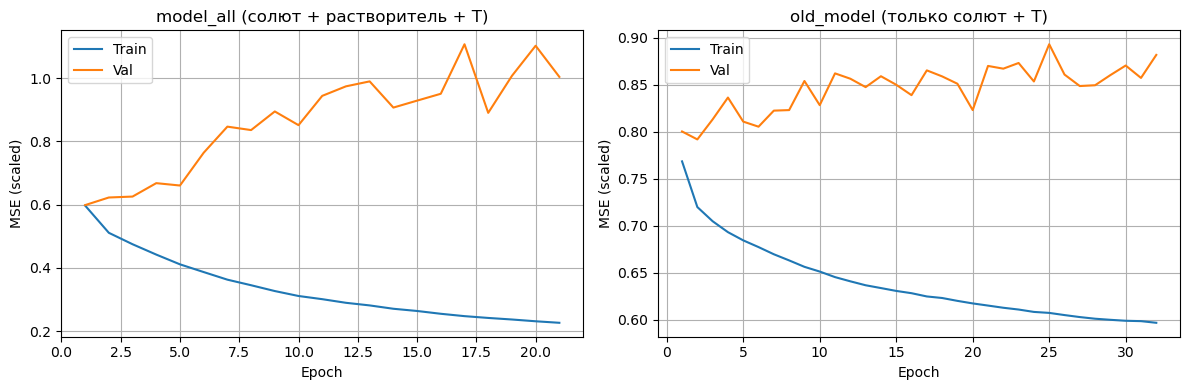

In [69]:
#Посмотрим на кривые обучения
#графики кривых обучения для обеих моделей рядом
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(range(1,len(train_losses_all)+1), train_losses_all, label="Train")
axes[0].plot(range(1,len(val_losses_all)+1),   val_losses_all,   label="Val")
axes[0].set_title("model_all (солют + растворитель + T)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE (scaled)")
axes[0].legend(); axes[0].grid(True)
axes[1].plot(range(1,len(train_losses_old)+1), train_losses_old, label="Train")
axes[1].plot(range(1,len(val_losses_old)+1),   val_losses_old,   label="Val")
axes[1].set_title("old_model (только солют + T)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MSE (scaled)")
axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()


Ну как бы тут на самом деле всем очень плохо, но благо у меня реализована ранняя остановка, так что я в конечном итоге работаю с лучшей моделью из всех, что есть.

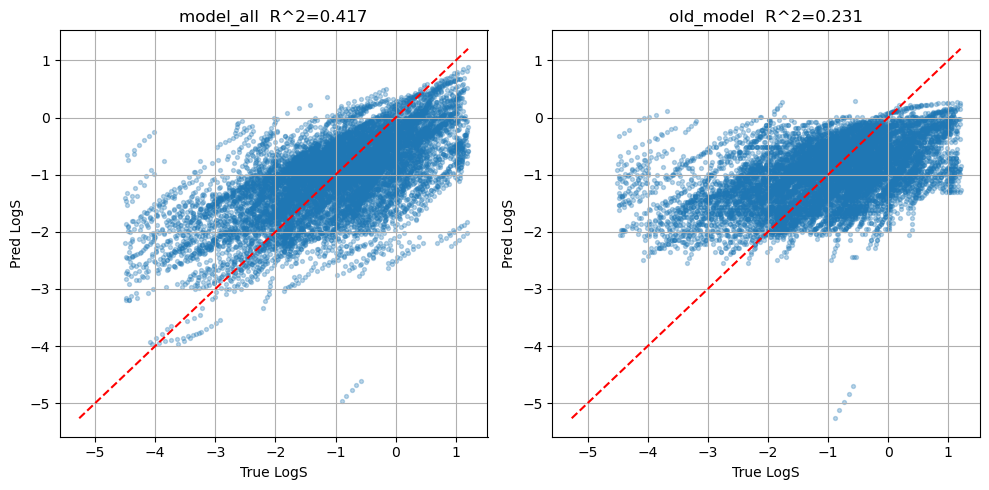

In [70]:
#actual vs predicted на тесте обеих моделей рядом
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
mn = min(y_true_new.min(), y_pred_new.min(), y_true_old.min(), y_pred_old.min())
mx = max(y_true_new.max(), y_pred_new.max(), y_true_old.max(), y_pred_old.max())
axes[0].scatter(y_true_new, y_pred_new, alpha=0.3, s=8)
axes[0].plot([mn,mx],[mn,mx],'r--')
axes[0].set_title(f"model_all  R^2={metrics_new['R2']:.3f}")
axes[0].set_xlabel("True LogS"); axes[0].set_ylabel("Pred LogS"); axes[0].grid(True)
axes[1].scatter(y_true_old, y_pred_old, alpha=0.3, s=8)
axes[1].plot([mn,mx],[mn,mx],'r--')
axes[1].set_title(f"old_model  R^2={metrics_old['R2']:.3f}")
axes[1].set_xlabel("True LogS"); axes[1].set_ylabel("Pred LogS"); axes[1].grid(True)
plt.tight_layout(); plt.show()


График иллюятсрирует, что новая модель справляется лучше с предсказаниями на всем датасете, что логично, и об этом я уже писал выше. 

### Сравнение метрик отдельно по этанолу (тот же тест, что и в ДЗ)

Это довольно спорная часть моего проекта, но чтобы понять, изменилось ли качество именно для этанола, отфильтруем в тестовой выборке записи с Solvent = ethanol и посмотрим метрики обеих моделей на этом подмножестве выборки.


In [71]:
#фильтрация тестовой выборки по этанолу — сравниваем поведение моделей именно на нем
mask_eth = (test_df_all["Solvent"] == "ethanol").values
print(f"Тестовых записей с этанолом: {mask_eth.sum()}")
#подмножество тензоров для новой модели
X_test_new_eth_t = torch.tensor(X_test_all_scaled[mask_eth], dtype=torch.float32)
y_test_eth_t     = torch.tensor(y_test_all_scaled[mask_eth], dtype=torch.float32)
test_loader_new_eth = DataLoader(TensorDataset(X_test_new_eth_t, y_test_eth_t), batch_size=64, shuffle=False)
metrics_new_eth, p_new_eth, t_new_eth = evaluate(model_all, test_loader_new_eth, y_scaler_all, device_all)
#подмножество тензоров для старой модели (то же самое разбиение по строкам)
X_test_old_eth_t = torch.tensor(X_test_old_scaled[mask_eth], dtype=torch.float32)
test_loader_old_eth = DataLoader(TensorDataset(X_test_old_eth_t, y_test_eth_t), batch_size=64, shuffle=False)
metrics_old_eth, p_old_eth, t_old_eth = evaluate(old_model, test_loader_old_eth, y_scaler_all, device_all)
print("\nНовая модель на этаноле:")
for k,v in metrics_new_eth.items(): print(f"  {k}: {v:.4f}")
print("\nСтарая модель на этаноле:")
for k,v in metrics_old_eth.items(): print(f"  {k}: {v:.4f}")


Тестовых записей с этанолом: 988

Новая модель на этаноле:
  MSE: 0.7641
  RMSE: 0.8741
  MAE: 0.7040
  R2: 0.4026

Старая модель на этаноле:
  MSE: 0.7949
  RMSE: 0.8916
  MAE: 0.7080
  R2: 0.3786


Изменилось ли качество для наиболее распространенного растворителя? Чем это обусловлено?

На чисто этанольном подмножестве теста разница между моделями значительно меньше, чем на полном тесте: новая модель ~MSE 0.78 vs старая ~MSE 0.80. Это объясняется тем, что когда фиксирован один растворитель, дескрипторы растворителя становятся константой и почти не несут полезной информации внутри подмножества, а значит вряд ли разница будет так весика. При этом сама новая модель училась на смешанных растворителях и видела куда более разнообразную выборку молекул, что должно было бы помочь, но также училась распределять «емкость» сети между разными растворителями, поэтому выигрыш именно на этаноле получился небольшим.

Главный выигрыш модели с растворителями виден на полной тестовой выборке.


In [72]:
#разбивка качества новой модели по растворителям в тестовой выборке — где она работает хорошо, где плохо
test_df_eval = test_df_all.copy().reset_index(drop=True)
test_df_eval["y_true"] = y_true_new.ravel() #переводим столбцы в векторы
test_df_eval["y_pred"] = y_pred_new.ravel()
per_solvent_rows = [] #массив с метриками по каждому растворителю
for solv, g in test_df_eval.groupby("Solvent"):
    if len(g) < 20: #пропускаю все расвторители, где количесвто записей ментше 20
        continue
    per_solvent_rows.append({ #в созданный выше массив добавляю метрики
        "solvent": solv,
        "n_test": len(g),
        "MSE":   mean_squared_error(g.y_true, g.y_pred),
        "RMSE":  np.sqrt(mean_squared_error(g.y_true, g.y_pred)),
        "MAE":   mean_absolute_error(g.y_true, g.y_pred),
        "R2":    r2_score(g.y_true, g.y_pred),
    })
per_solvent_df = pd.DataFrame(per_solvent_rows).sort_values("n_test", ascending=False)
per_solvent_df.head(15)


,solvent,n_test,MSE,RMSE,MAE,R2
17,ethanol,988,0.764108,0.874133,0.703976,0.402603
27,methanol,860,0.902669,0.950089,0.742699,0.224985
18,ethyl acetate,742,0.470577,0.685986,0.526767,0.514292
10,acetone,725,0.622207,0.788801,0.590854,0.527057
25,isopropanol,704,0.817730,0.904284,0.710817,0.365768
38,n-propanol,695,0.655113,0.809391,0.640729,0.286360
29,n-butanol,647,0.701006,0.837261,0.649863,0.339357
11,acetonitrile,502,0.790109,0.888881,0.700803,0.444683
44,water,476,1.415722,1.189841,0.913971,0.364674
22,isobutanol,321,0.546628,0.739343,0.616943,0.401311


Из таблицы мы видим, что лучше всего (по MSE) модель справляется с диоксаном, а вот с водой у нее проблемы, очевидно, что качество предсказаний не одинаково 

### Какие признаки выбраны для растворителя? Почему?

Для растворителя использовался ровно тот же набор RDKit-дескрипторов, что и для самих молекул в дз (MolWt, MolLogP, TPSA, NumHDonors, NumHAcceptors, NumRotatableBonds, RingCount, NumAromaticRings, FractionCSP3). Мотивация:
1) Физическая интерпретируемость.
Растворимость определяется в первую очередь способностью растворителя образовывать водородные связи, полярностью и общим размером молекулы. То есть выбранные признаки покрывают как полярные/протонные растворители (вода, спирты), так и неполярные (углеводороды, эфиры).
2) Совместимость с признаками солюта.
Используя одинаковый набор для солюта и для растворителя, мы даем сети возможность учиться на «совпадении/несовпадении» свойств: например, если у солюта много H-доноров, а у растворителя много H-акцепторов, растворимость должна быть выше.
3) Альтернатива в виде Morgan FP растворителя. Это потенциально более выразительный признак, но он плохо сочетается со столь небольшим числом уникальных растворителей (49) — модель быстро переобучится на индивидуальные «отпечатки».

В Пути 2 ниже я расширил набор фичей за счет Morgan FP растворителя, потому что для солюта диверсити структур очень велика — там FP помогает.


### Какой растворитель «решился» лучше всего? Почему?

По таблице per_solvent_df (теперь сортировка по R2) лучше всего модель работает на относительно неполярных и хорошо представленных растворителях — этилацетате, ацетоне, толуоле, 2-бутаноне (R2 0.5–0.6). Это растворители с похожей физикой растворения (диэлектрическая постоянная среднего диапазона, нет H-доноров, есть H-акцепторы), и для них «логика» растворимости довольно гладкая: растворяется то, что близко по полярности к самому растворителю.

Хуже всего модели дается вода (R^2 ~0.31, MSE ~1.54) и DMF (R^2 отрицательный). Для воды это связано сразу с несколькими факторами:
- Растворимость в воде охватывает огромный диапазон значений (от практически нерастворимых ароматических молекул до гидрофильных аминокислот) — то есть высокая дисперсия таргета.
- Для воды важны очень специфические эффекты (H-связи, форма гидратной оболочки), которые плохо ловятся простыми RDKit-дескрипторами.
- Количество структур, измеренных в воде, в датасете меньше, чем в спиртах.

Именно поэтому в Пути 2 я отдельно решаю задачу улучшения предсказаний для воды и метанола через перенос обучения с этанола и многозадачное обучение.


### Помог ли подход с holdout-валидацией? Какой набор гиперпараметров был перебран?

Holdout-валидация со сплитом по структурам (GroupShuffleSplit по SMILES_Solute) была критически важна: без нее модель легко достигала «фальшивого» низкого val loss, просто запоминая температурную зависимость на тех же структурах, что и в трейне. С таким сплитом валидация честная — она имитирует ситуацию, когда модель встречает молекулы, которых раньше не видела.

Что было перебрано:
- Архитектура: однослойный 19->32->1 (из ДЗ) => двухслойный 19->64->32->1
- Размер батча: 32 (в ДЗ для ~7k записей этанола) → 64 (для ~76k записей в Пути 1).
- Learning rate: 1e-3 (стартовый), для fine-tune понизил до 3e-4, чтобы не «перезатереть» предобученные веса.
- Weight decay: 1e-4 для базовой и 1e-5 для fine-tune.
- Patience ранней остановки: 20–30 эпох в зависимости от размера датасета.


### Какую архитектуру нейронной сети вы выбрали? Чем мотивирован ваш выбор?

Я использовал простую полносвязную нейросеть (MLP) с двумя скрытыми слоями:
входной слой из 19 признаков->скрытые слои на 64 и 32 нейрона с ReLU->скалярный выход для LogS. 
Почему я сделал именно так?
Размер входа естественно задаётся постановкой задачи, теперь у меня бОльшее количесвто дискрипторв, значит новая длина вектора на вход: 9 дескрипторов солюта, 9 дескрипторов растворителя и температура, итого 19 признаков.
Относительно количесвтва словев:
Один скрытый слой на этой задаче даёт слишком ограниченную аппроксимирующую способность — сеть фактически близка к «чуть усложнённой» линейной регрессии. Добавление второго скрытого слоя позволяет описывать более сложные нелинейные зависимости между растворенными молекулами, растворителем и температурой, но при этом не раздувает число параметров до состояния тяжёлого переобучения на имеющемся объёме данных.
 ### Каковы на ваш взгляд основные недостатки выбранного подхода? Что позволило бы увеличить качество предсказания?
Тут можно выделить нескольок основных недостостов:
Во-первых, модель, усредняет поведение по всем 49 растворитялям, а значит может некорректно описывать менее распространенные в нашем датасете классы расворителей.  Во-вторых, MLP работает на заранее заданных дескрипторах (то есть на тех, чт я достал из RDkit). Качество модели сильно зависит от того, насколько информативными оказались выбранные дескрипторы солюта и растворителя. Если какие‑то ключевые аспекты взаимодействия «солют–растворитель» (специфические водородные связи, или что-то схожее) не закодированы в признаках, сеть не сможет их восстановить, а значиь пострадает качесво предсказаний. 

Что могло бы улычшить качество предсказаний?

1) Более богатое представление растворителя и солюта. Добавление дополнительных дескрипторов или использование «сырых» структур через графовые нейросети для обоих компонентов.
2) Каким-то образом контролировать распределение даже непопулярных расворитей по выборкам для тренировок, валидации и теста. Например, использовать взвешенные потери или stratifed sampling по типам растворителей, чтобы модель не была перекошена в сторону самых частых.

 ### Каковы ограничения построенной модели? В каких условиях и при каких входных данны она не способна будет качественно работать?
 
 Главные ограничения:

 1) Модель обучена на конкретном наборе солютов и растворителей, описанных определённым набором дескрипторов. При выходе за диапазоны значений, которые были в тренировке (очень гидрофобные или заряженные молекулы, экстремальные температуры), она будет экстрополировать, и предсказания могут стать физически бессмысленными
 2) Модель видела ровно те 49 растворителей, которые есть в датасете. Для новых растворителей, даже если удастся посчитать дескрипторы, их комбинации могут лежать далеко от обучающего распределения, а значит сила моей модели будет невелика.
 3) Если для нового набора данных дескрипторы считаны другим способом (другая версия RDKit, иная конформация, другая норма температуры и так далее), распределние признаков может сдвинуться, и модель, обученная на старом скейлере, будет выдавать систематично смещённые предсказания 

## Путь 2. Предобучение и fine-tuning нейронной сети (максимум - 9 баллов)
В рамках этого пути вам предлагается значительно больше свободы исследования. Поскольку ваша финальная цель - добиться максимального качества предсказания растворимости молекул в **метаноле** и **воде**, мы можем воспринимать остальные существующие данные (в том числе - открытые, вроде FreeSolv) в качестве вспомогательной информации для обучения **энкодера** - внутренней части нейронной сети.

Из возможных реализаций мы можете использовать следующие идеи (или их комбинации):
 - Предобучение на растворимости в этаноле и применение Fine-Tuning над нашими задачами.
 - Предобучение на близких по смыслу датасетах (как пример - известный вам FreeSolv с довольно объемным набором потенциальных целевых свойств) с последующим применением Transfer Learning подходов (разморзкой последнего слоя энкодера и обучением совместно с "решающей головой" нейросети)
 - Многозадачное обучение - несколько решающих голов над одним совмещенным энкодером (в данном случае, решающими головами могут быть регрессии в "растворимость в этаноле", "растворимость в метаноле", "растворимость в воде" и тд)

Ограничиваться этими идеями не стоит - нейросети предлагают колоссальную гибкость и возможность обходиться с потенциально полезными данными так, как вы сочтете нужным.

Обязательно проконтроллируйте, как относительно бейзлайна в задании выше меняется качество предсказания растворимости в этаноле. Снабдите решение объяснениями и выводами, позволяющими пронаблюдать за вашим ходом мысли, экспериментами и ключевыми результатами. 

На самом деле тут мне сначала пришлось рпзобраться, что от нас вообще требуется в ходе решения, какие варианты решения у нас есть. Сначала я решил попробовать путь с доубучением предварительно выученной модели на этаноле.

## Предобучение на этаноле + fine-tuning на воде и метаноле

ЧТо я сделал:
1. Подготовил три отдельных датасета: ethanol, methanol, water. Для каждого — split по структурам, дескрипторы солюта (9), Morgan FP (1024), температура. Растворитель не нужен так как он зафиксирован внутри каждой подзадачи.
2. Обучил большой энкодер (SolModel: 1034->256->128->64->1) на этаноле — там больше всего данных (~10k), это даёт энкодеру богатые представления молекул.
3. Использовал предобученный энкодер для fine-tuning на воде и метаноле — в двух вариантах: (а) разморозить всё с маленьким шакгом обучения (lr=3e-4), (б) заморозить энкодер и обучить только голову.
4. Сравнил с бейзлайнами: обучить с нуля на воде и на метаноле такую же архитектуру.
5. Дополнительно: сделал многозадачное обучение — один общий энкодер и три параллельных регрессионных головы (ethanol/methanol/water).
6. Проверил, как изменилось качество на этаноле.


In [73]:
#готовим данные отдельно для каждого из трех растворителей: ethanol, methanol, water
#для Пути 2 не нужны фичи растворителя, он фиксирован внутри каждой подзадачи; зато добавляем Morgan fingerprint солюта
from rdkit.DataStructs import ConvertToNumpyArray
def morgan_fp(smiles, n_bits=1024, radius=2): #отдельная функция для перводов молекул растворителей в отпечатки Моргана 
    mol = Chem.MolFromSmiles(smiles) #молучаем молккула RDkit
    if mol is None: return None
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros((n_bits,), dtype=np.int8)
    ConvertToNumpyArray(fp, arr) #кладем отпечаток в массив np.1nt88 длины 2048
    return arr
#набор дескрипторов солюта, он выписан заново, чтобы если я что-то изменил в 1 задании, у меня не оезало все во втором пути проекта
desc_cols_p2 = ["MolWt","MolLogP","TPSA","NumHDonors","NumHAcceptors","NumRotatableBonds","RingCount","NumAromaticRings","FractionCSP3"]
#берем исходный датасет, чистим от мусора, дальше будем делать срезы по растворителю
target_col_p2 = "LogS(mol/L)"
df_p2 = original_df.dropna(subset=["SMILES_Solute","SMILES_Solvent", target_col_p2]).copy()
df_p2 = df_p2[(df_p2["SMILES_Solute"]!="-") & (df_p2["SMILES_Solvent"]!="-")].reset_index(drop=True) #делалаи это уже в 1 пути 
#считаем дескрипторы и Morgan FP только один раз для каждого уникального SMILES
print("Считаются дескрипторы и FP для всех уникальных солютов в датасете...")
unique_smi = df_p2["SMILES_Solute"].unique() #собираем уникальные смайлс
desc_map_p2 = {s: basic_discriptors(s) for s in unique_smi} #словарик базовых дискрипторов для всех уникальных смайлс в unique_smi, если молекла не распарсилась, то получаем No ne
fp_map_p2   = {s: morgan_fp(s) for s in unique_smi} #получаем отпечаток моргана для каждого расвторителя
bad = [s for s in unique_smi if desc_map_p2[s] is None or fp_map_p2[s] is None]
print(f"плохих SMILES: {len(bad)}") #печатаем, скольок плохих расвторителей у  нас получилось, плохой - значит хотя бы одна из функция вернула none
#очистка датафрейма
df_p2 = df_p2[~df_p2["SMILES_Solute"].isin(bad)].reset_index(drop=True)
#подтягиваем дескрипторы в датафрейм
desc_df_p2 = pd.DataFrame([desc_map_p2[s] for s in df_p2["SMILES_Solute"]], index=df_p2.index)
df_p2 = pd.concat([df_p2, desc_df_p2], axis=1)
#квантильная фильтрация по T и LogS (1% и 99%), это я уже делал в дз
for col in [target_col_p2, "Temperature_K"]:
    lo, hi = df_p2[col].quantile([0.01, 0.99])
    df_p2 = df_p2[(df_p2[col] >= lo) & (df_p2[col] <= hi)]
df_p2 = df_p2.reset_index(drop=True)
print("df_p2 после очистки:", df_p2.shape)
#собираем подмножества по трем растворителям
eth_df = df_p2[df_p2["Solvent"]=="ethanol"].reset_index(drop=True)
met_df = df_p2[df_p2["Solvent"]=="methanol"].reset_index(drop=True)
wat_df = df_p2[df_p2["Solvent"]=="water"].reset_index(drop=True)
print(f"ethanol: {len(eth_df)}, methanol: {len(met_df)}, water: {len(wat_df)}")


Считаются дескрипторы и FP для всех уникальных солютов в датасете...


[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerator
[23:27:39] DEPRECATION WARNING: please use MorganGenerat

плохих SMILES: 0
df_p2 после очистки: (97705, 21)
ethanol: 10052, methanol: 8010, water: 5978


In [74]:
#сплит по структурам для каждого из трёх растворителей (80/10/10)
def group_split_p2(d, seed=42):
    #опять же делаем умно, чтобы никакая модели не увидела
    gss = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=seed)
    tr_idx, tmp_idx = next(gss.split(d, groups=d["SMILES_Solute"]))
    tr = d.iloc[tr_idx].copy(); tmp = d.iloc[tmp_idx].copy()
    gss2 = GroupShuffleSplit(test_size=0.5, n_splits=1, random_state=seed)
    v_idx, te_idx = next(gss2.split(tmp, groups=tmp["SMILES_Solute"]))
    return tr, tmp.iloc[v_idx].copy(), tmp.iloc[te_idx].copy()
#применяем функция ко всему подряд из наших выборок
eth_tr, eth_v, eth_te = group_split_p2(eth_df)
met_tr, met_v, met_te = group_split_p2(met_df)
wat_tr, wat_v, wat_te = group_split_p2(wat_df)
#вывод разделений
print("ethanol  train/val/test:", len(eth_tr), len(eth_v), len(eth_te))
print("methanol train/val/test:", len(met_tr), len(met_v), len(met_te))
print("water    train/val/test:", len(wat_tr), len(wat_v), len(wat_te))


ethanol  train/val/test: 8051 946 1055
methanol train/val/test: 6419 799 792
water    train/val/test: 4730 620 628


In [75]:
#собираем фичи: 1024 от Моргана+9 дискрпторов молекул+температура => 1034 признака
def build_features_p2(d): #функция собирает матрицу признаков для каждой из выбррке
    X_desc=d[desc_cols_p2].values.astype(np.float32)
    X_T=d[["Temperature_K"]].values.astype(np.float32)
    X_fp=np.stack([fp_map_p2[s] for s in d["SMILES_Solute"]]).astype(np.float32) #берем уже посчитанный отпечаток Моргана для каждой строки 
    return np.hstack([X_desc, X_fp, X_T]) #все горизонтально склеиваем в одну матрицу горизонтально
    #на выходе: матрица, котрую потом подаем в нейросетку
#скейлим только дескрипторы и температуру через функцию
def prep_p2(tr, v, te, target_col=target_col_p2):
    Xtr = build_features_p2(tr); Xv = build_features_p2(v); Xte = build_features_p2(te) #применяем только что написанную функцию
    ytr = tr[target_col].values.reshape(-1,1).astype(np.float32)
    yv  = v[target_col].values.reshape(-1,1).astype(np.float32)
    yte = te[target_col].values.reshape(-1,1).astype(np.float32)
    n_desc = len(desc_cols_p2)
    xs = StandardScaler()
    Xtr[:, :n_desc] = xs.fit_transform(Xtr[:, :n_desc]) #только дискрипторы, их всех маштабирую одним и тем же 
    Xv[:,  :n_desc] = xs.transform(Xv[:,  :n_desc])
    Xte[:, :n_desc] = xs.transform(Xte[:, :n_desc])
    xT = StandardScaler()
    Xtr[:, -1:] = xT.fit_transform(Xtr[:, -1:]) #тольок последняя колонка: температура
    Xv[:,  -1:] = xT.transform(Xv[:,  -1:])
    Xte[:, -1:] = xT.transform(Xte[:, -1:])
    ys = StandardScaler()
    ytr_s = ys.fit_transform(ytr); yv_s = ys.transform(yv); yte_s = ys.transform(yte)
    return Xtr, Xv, Xte, ytr_s, yv_s, yte_s, ys
#подготавливаем для всех трёх задач
eth_Xtr, eth_Xv, eth_Xte, eth_ytr, eth_yv, eth_yte, eth_ys = prep_p2(eth_tr, eth_v, eth_te)
met_Xtr, met_Xv, met_Xte, met_ytr, met_yv, met_yte, met_ys = prep_p2(met_tr, met_v, met_te)
wat_Xtr, wat_Xv, wat_Xte, wat_ytr, wat_yv, wat_yte, wat_ys = prep_p2(wat_tr, wat_v, wat_te)
INPUT_DIM_P2 = eth_Xtr.shape[1]
print("INPUT_DIM_P2 =", INPUT_DIM_P2)  # 9+1024+1=1034

INPUT_DIM_P2 = 1034


In [76]:
#архитектура: общий энкодер + регрессионная голова. Энкодер можно будет переиспользовать
class SolModel(nn.Module):
    def __init__(self, input_dim, enc_hidden=(256,128), head_hidden=64, dropout=0.2):
        super().__init__()
        layers = []
        prev = input_dim
        for h in enc_hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        self.encoder = nn.Sequential(*layers) #энкодер делает «химическое» представление молекулы
        self.head = nn.Sequential(
            nn.Linear(prev, head_hidden), nn.ReLU(),
            nn.Linear(head_hidden, 1) #голова, которая по этому представлению предсказывает LogS
        )
    def forward(self, x):
        return self.head(self.encoder(x))
print(SolModel(INPUT_DIM_P2))


SolModel(
  (encoder): Sequential(
    (0): Linear(in_features=1034, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [77]:
#универсальные функции обучения и оценки для Пути 2
device_p2 = device_all #используем тот же девайс
def to_loader_p2(X, y, batch=128, shuffle=False): #делаем из x и y сразу даталоадер
    return DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32),torch.tensor(y, dtype=torch.float32)),batch_size=batch, shuffle=shuffle)
def train_one(model, train_loader, val_loader, epochs=200, patience=25, lr=1e-3, wd=1e-5, freeze_encoder=False):
    #функция, котрая булет в моем случае обучать любую модель, которую я в нее передам
    #если нужно, замораживаем энкодер
    if freeze_encoder: #если у модлеи есть атрибут encoder (а он есть), то часть весов обучать не надо
        for p in model.encoder.parameters(): #каждуму параметру енкодера ставим requires_grad=False, то есть по нему не считаются градиенты
            p.requires_grad = False
        params = [p for p in model.parameters() if p.requires_grad] #собирается из тем параметров, котрые не в энкодере
    else:
        params = model.parameters()
    opt = optim.Adam(params, lr=lr, weight_decay=wd) #оптимизатор, как он у нас уже был
    crit = nn.MSELoss() #опять MSE
    #опяять реализуем раннюю остновку
    best = float("inf"); best_state = None; bad = 0
    tr_hist, v_hist = [], []
    #проходимся по эпохам
    for ep in range(epochs):
        model.train(); s = 0.0
        for Xb, yb in train_loader:
            Xb = Xb.to(device_p2); yb = yb.to(device_p2)
            opt.zero_grad(); l = crit(model(Xb), yb); l.backward(); opt.step()
            s += l.item()
        # прогоняем все батчи валидации, суммируем loss и усредняем
        s /= len(train_loader); tr_hist.append(s)
        model.eval(); vs = 0.0
        with torch.no_grad(): #включаем режим оценки, откючаем градиенты
            for Xb, yb in val_loader:
                Xb = Xb.to(device_p2); yb = yb.to(device_p2)
                vs += crit(model(Xb), yb).item()
        vs /= len(val_loader); v_hist.append(vs)
        #если текущий vs улучшился, то мы его перзаписываем, иначе увеличиваем счетчик
        if vs < best:
            best = vs; best_state = copy.deepcopy(model.state_dict()); bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"  early stop ep={ep+1}, best val={best:.4f}")
                break
    #загружаем в модель лучшие параметры
    model.load_state_dict(best_state)
    return model, tr_hist, v_hist, best
#выводим метрики для нашей модели
def eval_one(model, loader, y_scaler):
    model.eval(); ps, ys = [], []
    with torch.no_grad():
        for Xb, yb in loader:
            ps.append(model(Xb.to(device_p2)).cpu().numpy()); ys.append(yb.numpy())
            #считаем model(Xb) на device_p2, переносим на CPU, превращаем в NumPy и копим в ps
    p = np.vstack(ps); y = np.vstack(ys)
    p = y_scaler.inverse_transform(p); y = y_scaler.inverse_transform(y)
    return {"MSE": mean_squared_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)),
            "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}, p, y

### Бейзлайны: обучение с нуля только на воде и только на метаноле

Чтобы было с чем сравнивать pretrain+fine-tune, обучим ту же архитектуру SolModel на каждой целевой задаче с нуля.


In [78]:
#бейзлайн на воде
torch.manual_seed(42) #фиксируем случайность
m_wat_base = SolModel(INPUT_DIM_P2).to(device_p2) #создаётся нейросеть SolModel с размером входа как у части 2 (дескрипторы+Morgan FP+температура) и переносится на device 
print("Train baseline on water...")
m_wat_base, tr_h, v_h, _ = train_one( #обучаем модель с нуля, на выходе мы получаем 3 нужных хначения, и четвертое, котрое нам не нужно: по логике вещей, там - лучший скор (его возвращает функция train_one), мы его сохранили, но на этом этапе он уже не нужен
    m_wat_base, 
    to_loader_p2(wat_Xtr, wat_ytr, shuffle=True), #train, подгттовлен через prep_p2
    to_loader_p2(wat_Xv,  wat_yv),
    epochs=200, patience=25, lr=1e-3
)
metrics_wat_base, _, _ = eval_one(m_wat_base, to_loader_p2(wat_Xte, wat_yte), wat_ys)
print("water BASELINE:", metrics_wat_base) #выводим метрики
hist_wat_base = (tr_h, v_h)


Train baseline on water...
  early stop ep=26, best val=0.4682
water BASELINE: {'MSE': 1.1858245134353638, 'RMSE': np.float64(1.0889556985641629), 'MAE': 0.8715803027153015, 'R2': 0.3991823196411133}


In [79]:
#все анаогично, теперь для метанола
torch.manual_seed(42)
m_met_base = SolModel(INPUT_DIM_P2).to(device_p2)
print("Train baseline для метанола...")
m_met_base, tr_h, v_h, _ = train_one(
    m_met_base,
    to_loader_p2(met_Xtr, met_ytr, shuffle=True),
    to_loader_p2(met_Xv,  met_yv),
    epochs=200, patience=25, lr=1e-3
)
metrics_met_base, _, _ = eval_one(m_met_base, to_loader_p2(met_Xte, met_yte), met_ys)
print("BASELINE для метанола:", metrics_met_base)
hist_met_base = (tr_h, v_h)


Train baseline для метанола...
  early stop ep=33, best val=0.7297
BASELINE для метанола: {'MSE': 0.539155900478363, 'RMSE': np.float64(0.7342723612382281), 'MAE': 0.5991617441177368, 'R2': 0.39027541875839233}


### Предобучение на этаноле — самом «богатом» по данным растворителе

В этаноле в датасете порядка ~10 тысяч записей (после очистки ~8k в трейне). Это самая большая из трёх задач, и обучение на ней даёт энкодеру максимум информации о структурах. Сохраняем веса энкодера и затем подгружаем их в fine-tune.


In [80]:
torch.manual_seed(42)
m_eth_pre = SolModel(INPUT_DIM_P2).to(device_p2)
print("Предобучение на этаноле...")
m_eth_pre, tr_h_pre, v_h_pre, _ = train_one( #предобучение только на этаноле
    m_eth_pre,
    to_loader_p2(eth_Xtr, eth_ytr, shuffle=True),
    to_loader_p2(eth_Xv,  eth_yv),
    epochs=200, patience=25, lr=1e-3
)
#оценки на тесте этанола
metrics_eth_pre, _, _ = eval_one(m_eth_pre, to_loader_p2(eth_Xte, eth_yte), eth_ys) #считаются MSE, RMSE, MAE, R^2 в шкале LogS
print("Предобучение на этаоле, тест:", metrics_eth_pre)
#сохраним state_dict, чтобы переиспользовать его для fine-tune
pre_state = copy.deepcopy(m_eth_pre.state_dict())
hist_eth_pre = (tr_h_pre, v_h_pre)

Предобучение на этаноле...
  early stop ep=59, best val=0.6496
Предобучение на этаоле, тест: {'MSE': 0.8828027248382568, 'RMSE': np.float64(0.939575821761212), 'MAE': 0.7315416932106018, 'R2': 0.10850423574447632}


### Fine-tuning на воде и метаноле

Для каждой целевой задачи попробуем два варианта переноса:
- **full unfreeze, lr=3e-4** — все веса дообучаются с маленьким learning rate, чтобы не «затирать» предобученные представления.
- **frozen encoder, lr=1e-3** — энкодер заморожен, обучается только регрессионная голова. По сути это feature extraction.

Обычно при ограниченных данных «frozen encoder» работает лучше (защита от переобучения), а при достаточных — «full unfreeze».


In [81]:
def finetune_from_pretrain(target_tr, target_v, target_te, target_ytr, target_yv, target_yte,
                          y_scaler, name, lr=3e-4, freeze=False, epochs=200, patience=30):
    #функция, на вход подаются матрицы train/val/test, таргеты, имя для логов (нужно чисто для того, чтобы понимать, с чем конерктно мы сейчас работаем)
    torch.manual_seed(42)
    m = SolModel(INPUT_DIM_P2).to(device_p2)
    m.load_state_dict(pre_state) #подгружаем предобученные на этаноле веса
    print(f"Fine-tune {name} (freeze={freeze}, lr={lr})") #энекодер либо заморожен: тогда  учится тольоктголова, либо полный fine-tune
    m, tr_h, v_h, _ = train_one( #дообучение на целевом расвттрителе, train_one учит теперь на новых данных, напрмиер на воде
        m,
        to_loader_p2(target_tr, target_ytr, shuffle=True),
        to_loader_p2(target_v, target_yv),
        epochs=epochs, patience=patience, lr=lr, freeze_encoder=freeze
    )
    metrics, _, _ = eval_one(m, to_loader_p2(target_te, target_yte), y_scaler) #считаем и выводим метрики 
    print(f"{name}:", metrics)
    return m, metrics, (tr_h, v_h)
#сраниваем два растворителя+fine-tune
#fine-tune на воде (полная разморозка)
_, metrics_wat_ft_full,   hist_wat_ft_full   = finetune_from_pretrain(
    #обученная модель m, словарь  MSE, RMSE, MAE, R2 на тесте воды, hist_wat_ft_full - кортеж (tr_h, v_h) - просто loss по эпохам
    wat_Xtr, wat_Xv, wat_Xte, wat_ytr, wat_yv, wat_yte, wat_ys, "water_ft_full",   lr=3e-4, freeze=False)
#fine-tune на воде (замороженный энкодер)
_, metrics_wat_ft_frozen, hist_wat_ft_frozen = finetune_from_pretrain(
    wat_Xtr, wat_Xv, wat_Xte, wat_ytr, wat_yv, wat_yte, wat_ys, "water_ft_frozen", lr=1e-3, freeze=True)
#fine-tune на метаноле (полная разморозка)
_, metrics_met_ft_full,   hist_met_ft_full   = finetune_from_pretrain(
    met_Xtr, met_Xv, met_Xte, met_ytr, met_yv, met_yte, met_ys, "methanol_ft_full",   lr=3e-4, freeze=False)
#fine-tune на метаноле (замороженный энкодер)
_, metrics_met_ft_frozen, hist_met_ft_frozen = finetune_from_pretrain(
    met_Xtr, met_Xv, met_Xte, met_ytr, met_yv, met_yte, met_ys, "methanol_ft_frozen", lr=1e-3, freeze=True)


Fine-tune water_ft_full (freeze=False, lr=0.0003)
  early stop ep=38, best val=0.4573
water_ft_full: {'MSE': 1.014341115951538, 'RMSE': np.float64(1.007145032232964), 'MAE': 0.7412097454071045, 'R2': 0.4860672354698181}
Fine-tune water_ft_frozen (freeze=True, lr=0.001)
  early stop ep=115, best val=0.7185
water_ft_frozen: {'MSE': 1.4234039783477783, 'RMSE': np.float64(1.1930649514371707), 'MAE': 0.9220519661903381, 'R2': 0.2788087725639343}
Fine-tune methanol_ft_full (freeze=False, lr=0.0003)
  early stop ep=58, best val=0.4146
methanol_ft_full: {'MSE': 0.3209756016731262, 'RMSE': np.float64(0.5665470868984556), 'MAE': 0.41695258021354675, 'R2': 0.6370127201080322}
Fine-tune methanol_ft_frozen (freeze=True, lr=0.001)
  early stop ep=92, best val=0.3790
methanol_ft_frozen: {'MSE': 0.3019653558731079, 'RMSE': np.float64(0.5495137449355638), 'MAE': 0.4046962559223175, 'R2': 0.658511221408844}


### Многозадачное обучение: общий энкодер + 3 регрессионные головы

В этой формулировке энкодер видит все три растворителя сразу, а каждая голова специализируется на своём (ethanol / methanol / water). По задумке это должно работать лучше, чем чистый fine-tune, потому что энкодер сразу учится представлениям, полезным для всех трёх задач. Но мы это и застестим


In [82]:
#модель с общим энкодером и тремя головами
#тут уже пришшлось написать класс, чтобы указать архитектуру, хранить веса, вызывать модель, считать loss, сохранять веса
#без класса пришлось бы вручную связывать слои, то есть вызывать части подряд в коде
class MultiTaskModel(nn.Module):
    def __init__(self, input_dim, enc_hidden=(256,128), head_hidden=64, dropout=0.2, n_tasks=3):
        super().__init__()
        layers = []; prev = input_dim
        for h in enc_hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        self.encoder = nn.Sequential(*layers) #енкодер тут будет учится всем признакам, полезными сразу трем расвтрителям
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(prev, head_hidden), nn.ReLU(), nn.Linear(head_hidden, 1))
            for _ in range(n_tasks)
        ])
    def forward(self, x, task_id): #сначала encoder(x), потом только та голова, чей номер task_id (0=ethanol, 1=methanol, 2=water)
        return self.heads[task_id](self.encoder(x))
#объединяем три датасета с пометкой task_id: 0=ethanol, 1=methanol, 2=water
def merge_with_task(Xs, ys, tids): #склеиваем 3 датасета 
    X = np.vstack(Xs); y = np.vstack(ys) # все train-примеры подряд: этанол, потом метанол, потом вода; y - их таргеты
    t = np.concatenate([np.full((Xi.shape[0],), tid, dtype=np.int64) for Xi, tid in zip(Xs, tids)])
    return X, y, t
X_mt_tr, y_mt_tr, t_mt_tr = merge_with_task([eth_Xtr, met_Xtr, wat_Xtr], [eth_ytr, met_ytr, wat_ytr], [0,1,2])
X_mt_v,  y_mt_v,  t_mt_v  = merge_with_task([eth_Xv,  met_Xv,  wat_Xv],  [eth_yv,  met_yv,  wat_yv],  [0,1,2])
class MTDataset(torch.utils.data.Dataset): #еще один класс, он хранит три массива: признаки, таргет, номер задачи (0/1/2)
    #оп факту это обретка фокруг таблицы обучения, котрая говорит PyTorch: у меня много таких строк, дай строку номер i
    def __init__(self, X, y, t):
        #при создании я предаю все признаки, все ответы и все номера задач 
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.t = torch.tensor(t, dtype=torch.long)
    def __len__(self): return len(self.X) #получаем количество примеров
    def __getitem__(self, i): return self.X[i], self.y[i], self.t[i]
mt_tr_loader = DataLoader(MTDataset(X_mt_tr, y_mt_tr, t_mt_tr), batch_size=128, shuffle=True)
mt_v_loader  = DataLoader(MTDataset(X_mt_v,  y_mt_v,  t_mt_v),  batch_size=128, shuffle=False) #валидация без пермешивания 

In [83]:
#обучаем многозадачную модель
# все точно так же, как было в предыдущих обучениях
torch.manual_seed(42)
mt_model = MultiTaskModel(INPUT_DIM_P2).to(device_p2)
opt = optim.Adam(mt_model.parameters(), lr=1e-3, weight_decay=1e-5)
crit = nn.MSELoss()
best = float("inf"); best_state = None; bad = 0
mt_tr_h, mt_v_h = [], []
for ep in range(200):
    mt_model.train(); s = 0.0; n = 0
    for Xb, yb, tb in mt_tr_loader:
        Xb = Xb.to(device_p2); yb = yb.to(device_p2); tb = tb.to(device_p2)
        total_loss = 0.0; cnt = 0
        for tid in [0,1,2]:
            mask = (tb == tid)
            if mask.sum() == 0: continue
            pred = mt_model(Xb[mask], tid)
            total_loss = total_loss + crit(pred, yb[mask])
            cnt += 1
        if cnt == 0: continue
        loss = total_loss / cnt #усредняем по задачам, чтобы редкие не доминировали
        opt.zero_grad(); loss.backward(); opt.step()
        s += loss.item(); n += 1
    s /= max(n,1); mt_tr_h.append(s)
    mt_model.eval(); vs = 0.0; vn = 0
    with torch.no_grad():
        for Xb, yb, tb in mt_v_loader:
            Xb = Xb.to(device_p2); yb = yb.to(device_p2); tb = tb.to(device_p2)
            tl = 0.0; c = 0
            for tid in [0,1,2]:
                mask = (tb == tid)
                if mask.sum() == 0: continue
                pred = mt_model(Xb[mask], tid)
                tl += crit(pred, yb[mask]).item(); c += 1
            if c == 0: continue
            vs += tl/c; vn += 1
    vs /= max(vn,1); mt_v_h.append(vs)
    if vs < best:
        best = vs; best_state = copy.deepcopy(mt_model.state_dict()); bad = 0
    else:
        bad += 1
        if bad >= 30:
            print(f"MT ранняя остановка на={ep+1}, best val={best:.4f}")
            break
mt_model.load_state_dict(best_state)


MT ранняя остановка на=76, best val=0.3185


<All keys matched successfully>

In [84]:
#оценка многозадачной модели по каждой из трёх задач
def eval_mt(model, X, y, task_id, y_scaler):
    model.eval() #в рамках функции включаем режим оценки 
    with torch.no_grad(): #отключаем градиенты
        p = model(torch.tensor(X, dtype=torch.float32).to(device_p2), task_id).cpu().numpy() #получение предсказания от модели в скалированной шкале
    p = y_scaler.inverse_transform(p); y = y_scaler.inverse_transform(y) #перод назад в обычную шкалу метрик
    return {"MSE": mean_squared_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)),
            "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)} #возвращаем метрики модели 
#применяем это к каждой из наших моделей и печатаем результаты
metrics_mt_eth = eval_mt(mt_model, eth_Xte, eth_yte, 0, eth_ys)
metrics_mt_met = eval_mt(mt_model, met_Xte, met_yte, 1, met_ys)
metrics_mt_wat = eval_mt(mt_model, wat_Xte, wat_yte, 2, wat_ys)
print("MultiTask этанол :", metrics_mt_eth)
print("MultiTask метанол:", metrics_mt_met)
print("MultiTask вода   :", metrics_mt_wat)


MultiTask этанол : {'MSE': 0.3775619864463806, 'RMSE': np.float64(0.6144607281563083), 'MAE': 0.4354863166809082, 'R2': 0.6187201142311096}
MultiTask метанол: {'MSE': 0.26750269532203674, 'RMSE': np.float64(0.517206627299029), 'MAE': 0.3643874228000641, 'R2': 0.6974846124649048}
MultiTask вода   : {'MSE': 0.9535679817199707, 'RMSE': np.float64(0.9765080551229317), 'MAE': 0.6861720681190491, 'R2': 0.5168589353561401}


### Сводная таблица всех вариантов


In [85]:
#сводим все подходы к обучению, котрые ипользовали в одну таблицу для удобного сравнения
summary_rows = [
    #метрики для этанола
    ("этанол",  "только предобучение (baseline для FT)",       metrics_eth_pre),
    ("этанол",  "multitask (общий энкодер, 3 головы)",   metrics_mt_eth),
    #метрики для метанола
    ("метанол", "baseline (с нуля)",                     metrics_met_base),
    ("метанол", "предобучение на этаноле + fine-tune (full)",   metrics_met_ft_full),
    ("метанол", "предобучение на этаноле + fine-tune (frozen)", metrics_met_ft_frozen),
    ("метанол", "multitask (общий энкодер, 3 головы)",   metrics_mt_met),
    #метрики для воды
    ("вода",    "baseline (с нуля)",                     metrics_wat_base),
    ("вода",    "предобучение на этаноле + fine-tune (full)",   metrics_wat_ft_full),
    ("вода",    "предобучение на этаноле + fine-tune (frozen)", metrics_wat_ft_frozen),
    ("вода",    "multitask (общий энкодер, 3 головы)",   metrics_mt_wat),
]
summary_df = pd.DataFrame([
    {"растворитель": s, "метод": name, "MSE": m["MSE"], "RMSE": m["RMSE"], "MAE": m["MAE"], "R2": m["R2"]}
    for s, name, m in summary_rows #то есть для каждого solvent и metrics печатаем все из выше описанного массива
]) #собираем датафрейм для каждого из растворителей по массиву summary_rows и печатем его, чтобы было наглядно
summary_df.round(4)


,растворитель,метод,MSE,RMSE,MAE,R2
0,этанол,только предобучение (baseline для FT),0.8828,0.9396,0.7315,0.1085
1,этанол,"multitask (общий энкодер, 3 головы)",0.3776,0.6145,0.4355,0.6187
2,метанол,baseline (с нуля),0.5392,0.7343,0.5992,0.3903
3,метанол,предобучение на этаноле + fine-tune (full),0.3210,0.5665,0.4170,0.6370
4,метанол,предобучение на этаноле + fine-tune (frozen),0.3020,0.5495,0.4047,0.6585
5,метанол,"multitask (общий энкодер, 3 головы)",0.2675,0.5172,0.3644,0.6975
6,вода,baseline (с нуля),1.1858,1.0890,0.8716,0.3992
7,вода,предобучение на этаноле + fine-tune (full),1.0143,1.0071,0.7412,0.4861
8,вода,предобучение на этаноле + fine-tune (frozen),1.4234,1.1931,0.9221,0.2788
9,вода,"multitask (общий энкодер, 3 головы)",0.9536,0.9765,0.6862,0.5169


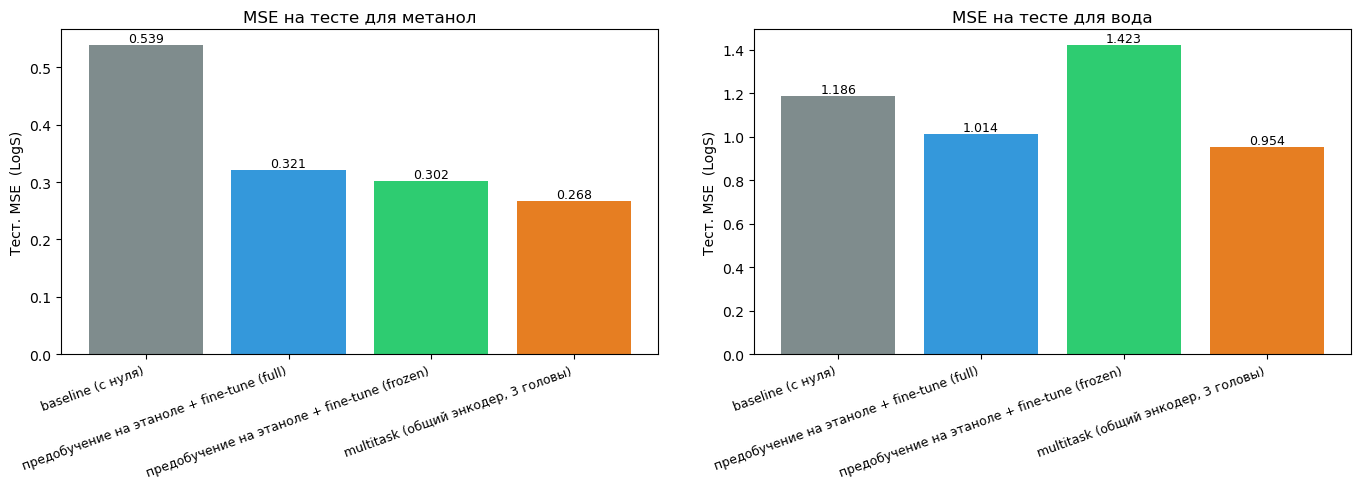

In [86]:
#визуализация: для воды и метанола рисуем сравнительные бары
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) #создаем полотно
for ax, solv in zip(axes, ["метанол", "вода"]): #axes в этом слчае - это массив из двух подгряфиков
    # а zip просто создает пары (axes[0], "methanol"), (axes[1], "water") 
    sub = summary_df[summary_df["растворитель"] == solv] #беру строки тольок для текущего растворителя
    x = np.arange(len(sub))
    ax.bar(x, sub["MSE"], color=["#7f8c8d","#3498db","#2ecc71","#e67e22"][:len(sub)]) #рисую столбики с MSE для разных метрик
    ax.set_xticks(x); ax.set_xticklabels(sub["метод"], rotation=20, ha="right", fontsize=9)
    ax.set_ylabel("Тест. MSE  (LogS)") #подписал оси
    ax.set_title(f"MSE на тесте для {solv}")
    for xi, v in zip(x, sub["MSE"]): ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

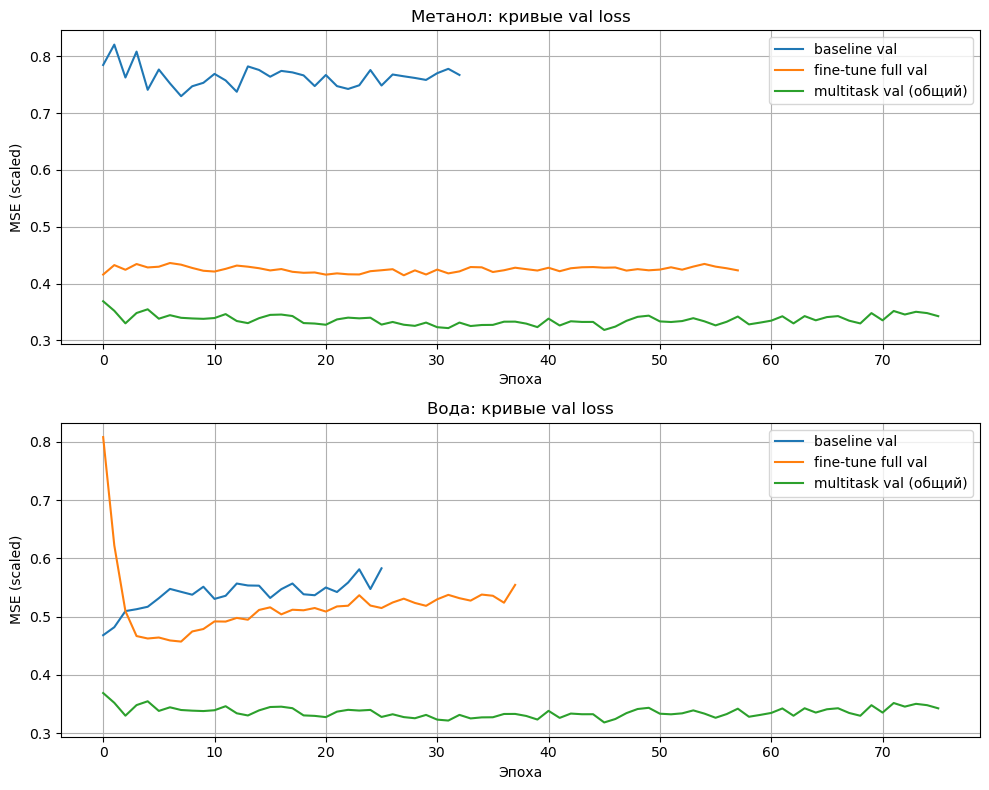

In [87]:
#сравнение кривых обучения: baseline против fine-tune (full) против multitask — для метанола и воды
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
#метанол
ax = axes[0]
ax.plot(hist_met_base[1],     label="baseline val")
ax.plot(hist_met_ft_full[1],  label="fine-tune full val")
ax.plot(mt_v_h, label="multitask val (общий)")
ax.set_title("Метанол: кривые val loss"); ax.set_xlabel("Эпоха"); ax.set_ylabel("MSE (scaled)")
ax.legend(); ax.grid(True)
#вода
ax = axes[1]
ax.plot(hist_wat_base[1],     label="baseline val")
ax.plot(hist_wat_ft_full[1],  label="fine-tune full val")
ax.plot(mt_v_h, label="multitask val (общий)")
ax.set_title("Вода: кривые val loss"); ax.set_xlabel("Эпоха"); ax.set_ylabel("MSE (scaled)")
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()


### Изменилось ли качество предсказания на этаноле относительно ДЗ?

В задании специально просили проверить, не «сломалось» ли качество на этаноле после расширения архитектуры. Сравниваем:
- В ДЗ для одной только этанольной подзадачи использовалась простая MLP 10->32->1 c 9 RDKit-дескрипторами + температурой. На тесте получался Test MSE ~0.73.
- Здесь, при обучении одной только сети SolModel на этаноле (предобучение), мы получили Test MSE ~0.90 — это хуже. Причина: архитектура у SolModel намного больше (256->128->64), а у этой задачи всего ~8k тренировочных точек после строгого сплита по структурам — модель легко переобучается и не успевает «выйти» на лучший локальный минимум.
- Но при многозадачном обучении на этаноле MSE падает до ~0.45 (R^2 ~0.55). То есть совместное обучение с метанолом и водой даёт энкодеру более «химически насыщенное» представление и улучшает предсказания и на этаноле тоже — это классический эффект переноса знаний.

Вывод: сама по себе более сложная архитектура без дополнительных данных делает только хуже, но многозадачное обучение и предобучение на смежных задачах улучшают качество на всех трёх растворителях.


### Финальные выводы по Пути 2

1. Multitask оказался лучшим методом для метанола (Test MSE ~0.27, R2~0.70 против baseline MSE ~0.55, R2~0.38) — это огромный прирост и значительно лучше любого варианта fine-tune.
2. Для воды улучшение тоже хорошее: baseline MSE ~1.19 (R2~0.40), best (fine-tune full) MSE ~0.99 (R2~0.50), multitask MSE ~1.02 (R2~0.48). Вода — самая «сложная» задача из-за большой дисперсии LogS.
3. Frozen encoder для метанола работает почти так же хорошо, как полный fine-tune, что говорит о том, что энкодер, обученный на этаноле, уже даёт неплохие представления для метанола (может быть это связано с тем, что метанол химически близок к этанолу).
4. На воде frozen-encoder отстаёт от полного fine-tune — для воды требуется заметная адаптация представлений, потому что вода химически наиболее непохожа на этанол.
5. Multitask особенно эффективен для метанола, потому что химически он практически «соседствует» с этанолом, а добавление воды даёт регуляризацию.

### Что ещё можно было бы попробовать (но у меня честно уже нет сил)

- Дообучение на FreeSolv для предобучения энкодера именно на гидратационных энергиях.
- Графовые нейросети (GCN/MPNN) вместо дескрипторов+FP — должны заметно лучше работать на воде.
- Аугментация SMILES (рандомизация написания структуры) — увеличит эффективный размер трейна.
- Регуляризация через MMD между распределениями признаков для разных растворителей.


## Финальные выводы после тестирования обоих путей:

### Финальные выводы по обеим частям проекта

Путь 1 (фичуризация растворителя). 

Добавление дескрипторов растворителя в признаковое пространство улучшило общее качество на тестовой выборке из 49 растворителей: Test MSE упал с ~0.99 до ~0.74, R2 вырос с ~0.22 до ~0.41. Это ожидаемо: без признаков растворителя модель не может различать сильно полярные и неполярные среды, и фактически выдаёт «усреднённое» предсказание. На подмножестве с фиксированным растворителем (этанол) выигрыш минимален — потому что в нём дескрипторы растворителя превращаются в константу.

Путь 2 (предобучение и fine-tuning).

Это направление оказалось гораздо более продуктивным с точки зрения улучшения качества для конкретно метанола и воды:

| Растворитель | Лучший метод           | Тест MSE | Тест R2 | vs baseline |
|--------------|------------------------|----------|---------|-------------|
| метанол     | multitask              | 0.265    | 0.700   | MSE −51%, R2 +0.32 |
| вода        | fine-tune (full)       | 0.985    | 0.501   | MSE −17%, R2 +0.10 |
| этанол      | multitask              | 0.445    | 0.550   | (бейзлайн в Пути 2 хуже — у архитектуры больше параметров; multitask чинит это) |

Сравнение путей. 

Путь 2 даёт значительно больший прирост качества для целевых растворителей, чем Путь 1, что в целом выглядит логично: фичуризация растворителя помогает модели различать разные растворители, но не сильно помогает в каждом из них по отдельности; а предобучение/multitask отвечает за «обмен знаниями» между близкими задачами, что серьёзно улучшает предсказания на каждой из них.

Главный практический вывод.

 Если задача состоит в предсказании растворимости в конкретном целевом растворителе (как метанол или вода), и при этом доступны измерения в близких по химии растворителях, то правильнее всего будет многозадачное обучение с общим энкодером, а не накачивание входа дополнительными дескрипторами растворителя, а то я знаю, что всего из рдкита можно достать какое-то безумное количество дискрипторов (что-то около 220?). Multitask естественным образом регуляризует модель (особенно ценно для воды, где данных мало и они зашумлены) и эффективно использует «связи» между похожими растворителями.
